# Инженерия признаков: прогнозирование покупки на сайте e-commerce

## 1. Титульный лист

**Дисциплина:** Машинное обучение и искусственный интеллект  
**Модуль 4:** Инженерия признаков и работа с нестандартными данными  
**Датасет:** *Online Shoppers Purchasing Intention*  
**Выполнила:** Володина Александра Александровна  
**Группа:** ПКТб-23-1  
**Преподаватель:** Спирин Игорь Сергеевич  
**Ссылка на репозиторий:** [VolodinaAlexandra/ml-course-volodina](https://github.com/VolodinaAlexandra/ml-course-volodina)  
**Путь к модулю:** module-4-features/notebook.ipynb  
**Дата сдачи:** 2026-11-02  
**Учебный год:** 2026/2027

## 2. Введение

**Задача:** бинарная классификация — определить, завершится ли сессия покупкой (Revenue=1). Для интернет-магазина оценка намерения полезна при анализе воронки, сегментации и выборе предложений. Датасет содержит итоговые агрегаты сессий: проверяем классификацию таких срезов, а не подтверждённый прогноз в момент первого захода.

**Инженерия признаков** переводит исходные измерения в характеристики, связанные с задачей. Суммарные просмотры, время и отношения могут упростить поиск зависимостей. Пользу производных признаков проверяем сравнением LightGBM с ними и без них на одинаковых CV-блоках.

**Метрики.** Постоянное «нет покупки» даёт Accuracy около 84,5%, поэтому основной показатель — ROC-AUC по вероятностям. F1 оценивает баланс Precision и Recall при пороге 0,5. Recall показывает, какую долю покупателей удалось найти, Precision — сколько предсказанных покупок верны. Рабочий порог требует стоимости ошибок и отдельной валидации.

**Цели работы:**

1. Создать минимум пять новых признаков; реализовать все восемь формул из задания.
2. Обучить Random Forest, XGBoost, LightGBM и CatBoost, сравнить качество и время.
3. Настроить LightGBM через Optuna, объяснить прогнозы через SHAP и проверить сохранённую модель из репозитория.

## 3. Теоретическая часть

### Инженерия признаков

Feature Engineering создаёт полезное для модели представление исходных данных. В IT это могут быть агрегаты поведения, категории устройств, сезонность и признаки логов. Хороший признак должен быть доступен в момент прогноза. Его полезность проверяют на данных, не участвовавших в настройке. Сложная модель не гарантирует, что добавленный признак улучшит качество, поэтому в работе предусмотрено контролируемое сравнение.

### Категориальные признаки

Label Encoding заменяет категории целыми кодами, но эти числа не обязательно имеют естественный порядок. One-Hot создаёт бинарный столбец для каждой категории и избегает такой трактовки. В работе One-Hot применяется к семи смысловым категориям, включая технические коды и Month. Список категорий изучается только по train, новые значения обрабатываются без переобучения на тесте.

### Временные признаки

Месяц, день недели и выходной могут отражать сезонность поведения. В датасете есть Month, Weekend и близость особого дня SpecialDay, но нет полной даты сессии. MonthNum создаётся явным словарём; MonthSin и MonthCos описывают цикличность года. По порядку строк нельзя выдумывать даты, историю клиента или межсессионные лаги.

### Поведенческие признаки

Сумма страниц показывает объём просмотра, а сумма длительностей — время взаимодействия. Отношение помогает сравнивать сессии разного масштаба. К знаменателям добавляются малые константы для защиты от нуля. Такой приём меняет смысл отношения и должен быть указан в формуле. Производные признаки могут быть избыточными: это проверяем на train CV.

### Дисбаланс классов

Покупки составляют меньшинство, поэтому Accuracy может скрывать пропуски покупателей. Веса классов увеличивают штраф за ошибки на положительном классе. SMOTE синтезирует обучающие примеры и должен применяться внутри обучающих CV-блоков, а для категорий нужна подходящая схема вроде SMOTENC. Веса могут ухудшать калибровку вероятностей, даже когда ROC-AUC высок.

### SHAP

Значения SHAP распределяют отличие ответа модели от базового ответа между признаками. Summary показывает направление и разброс вкладов, bar — средний абсолютный вклад. Waterfall объясняет один объект. Dependence связывает значение одного признака с вкладом. Для LightGBM здесь объясняется raw score в логитах, поэтому вклад нельзя называть прямой прибавкой к вероятности или причинным эффектом.

### Связь с лекцией о нестандартных данных

**TF-IDF** взвешивает слова по частоте в документе и редкости в корпусе; словарь и IDF оцениваются по обучающим документам. В этой практике нет свободного текста, поэтому им не кодируются искусственно названия месяцев.

$$\mathrm{TFIDF}(t,d)=\mathrm{TF}(t,d)\log\frac{N}{\mathrm{DF}(t)}.$$

**Haversine** даёт расстояние по сфере по координатам в радианах; DBSCAN объединяет плотные области и помечает шум как −1. Для геоданных корректно использовать Haversine и радиус eps в радианах, а не считать градусы одинаковыми километрами. Размер градуса долготы зависит от широты. Здесь Region — код категории, координат нет, поэтому вычислять расстояния по нему нельзя.

$$a=\sin^2\frac{\Delta\varphi}{2}+\cos\varphi_1\cos\varphi_2\sin^2\frac{\Delta\lambda}{2},\qquad d=2R\operatorname{atan2}(\sqrt a,\sqrt{1-a}).$$

**Лаги и окна** применимы к упорядоченным наблюдениям. Для прогноза в момент t используются прошлые данные, например shift(1).rolling(7).mean(); окно, включающее текущую целевую, создаёт утечку. В этом датасете нет последовательности наблюдений одного клиента, поэтому такие признаки остаются теоретическими.

### Ансамблевые модели

$$H_{\mathrm{bag}}(x)=\frac1M\sum_{i=1}^{M}h_i(x),\qquad
H_{\mathrm{boost}}(x)=\sum_{i=1}^{M}\alpha_i h_i(x).$$

В bagging ответы независимых базовых моделей усредняются; boosting последовательно улучшает композицию. Для бинарного бустинга суммарный логит переводится в вероятность сигмоидой.

| Модель | Подход | Основные параметры | Особенность |
|---|---|---|---|
| Random Forest | Bagging | деревья, глубина, размер листа | уменьшает разброс деревьев |
| XGBoost | Boosting | темп, глубина, L1/L2 | регуляризованная композиция |
| LightGBM | Boosting | листья, глубина, подвыборки | гистограммное обучение |
| CatBoost | Boosting | итерации, глубина, темп | поддерживает нативные категории; здесь общий One-Hot |

**Optuna** с TPE использует результаты прошлых испытаний для поиска перспективных параметров. Целевая функция — ROC-AUC на пяти блоках train; тест исключён из поиска.

## 4. Описание данных

**Источник:** [UCI Online Shoppers Purchasing Intention](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset), Sakar и Kastro (2018), DOI [10.24432/C5F88Q](https://doi.org/10.24432/C5F88Q), лицензия CC BY 4.0. Альтернативная ссылка из задания: [Kaggle](https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention).

**Структура исходного CSV:** 12 330 сессий, 17 признаков и целевая Revenue. По смыслу 10 числовых и 7 категориальных признаков, включая Month и Weekend. Технические коды OperatingSystems, Browser, Region и TrafficType являются категориями.

| Столбец | Тип | Содержание | Пропуски |
|---|---|---|---:|
| Administrative | int | административные страницы | 0 |
| Administrative_Duration | float | время на них, с | 0 |
| Informational | int | информационные страницы | 0 |
| ProductRelated | int | товарные страницы | 0 |
| ProductRelated_Duration | float | время на товарных страницах, с | 0 |
| BounceRates | float | показатель отказов | 0 |
| ExitRates | float | показатель выходов | 0 |
| PageValues | float | агрегированная ценность страниц | 0 |
| Month | строка | месяц сессии | 0 |
| VisitorType | строка | тип посетителя | 0 |
| Weekend | bool | выходной день | 0 |
| Revenue | bool | **целевая**, покупка | 0 |

**Классы до очистки:** False — 10 422 (84,53%), True — 1908 (15,47%). Подробности: data/dataset_info.md.

PageValues связан с транзакционной ценностью страниц; доступность его исторического значения на момент реального решения должна проверяться отдельно. Поэтому приведена дополнительная оценка без PageValues и его производного AvgPageValue.

In [11]:
# Импортируем средства анализа, обучения и сохранения артефактов.
import json  # Подключаем json
import time  # Подключаем time
import hashlib  # Подключаем hashlib
from io import BytesIO  # Подключаем io
from pathlib import Path  # Подключаем pathlib
from importlib.metadata import version  # Подключаем importlib.metadata
import joblib  # Подключаем joblib
import numpy as np  # Подключаем numpy
import pandas as pd  # Подключаем pandas
import matplotlib.pyplot as plt  # Подключаем matplotlib.pyplot
import seaborn as sns  # Подключаем seaborn
from sklearn.ensemble import RandomForestClassifier  # Подключаем sklearn.ensemble
from sklearn.model_selection import train_test_split, StratifiedKFold  # Подключаем sklearn.model_selection
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # Подключаем sklearn.preprocessing
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,  # Подключаем sklearn.metrics
                             roc_auc_score, confusion_matrix, roc_curve)
from xgboost import XGBClassifier  # Подключаем xgboost
from lightgbm import LGBMClassifier  # Подключаем lightgbm
from catboost import CatBoostClassifier  # Подключаем catboost

# Пути считаются относительно папки module-3-churn.
SEED = 42  # Фиксируем случайность
DATA, MODELS, EXAMPLES = Path('data'), Path('models'), Path('examples')  # Относительные папки
MODELS.mkdir(exist_ok=True)  # Артефакты моделей
EXAMPLES.mkdir(exist_ok=True)  # Папка рисунков
sns.set_theme(style='whitegrid', font='DejaVu Sans')  # Единый стиль

# Читаем исходную таблицу и проверяем обязательную структуру.
df = pd.read_csv(DATA / 'online_shoppers_intention.csv')
print(df.shape)  # Строки и столбцы.
print(df.head().to_string(index=False))  # Первые сессии.
assert df.shape == (12330, 18)  # Размер по заданию.
print(df.Revenue.value_counts().to_string())  # Число классов.
print((100*df.Revenue.value_counts(normalize=True)).round(2).to_string())  # Доли.

(12330, 18)
 Administrative  Administrative_Duration  Informational  Informational_Duration  ProductRelated  ProductRelated_Duration  BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  Browser  Region  TrafficType       VisitorType  Weekend  Revenue
              0                      0.0              0                     0.0               1                 0.000000         0.20       0.20         0.0         0.0   Feb                 1        1       1            1 Returning_Visitor    False    False
              0                      0.0              0                     0.0               2                64.000000         0.00       0.10         0.0         0.0   Feb                 2        2       1            2 Returning_Visitor    False    False
              0                      0.0              0                     0.0               1                 0.000000         0.20       0.20         0.0         0.0   Feb                 4        1       9  

## Вывод по описанию данных

Размер и классы совпадают с заданием. Отсутствие полной даты, текста и координат ограничивает применимость лекционных методов. Статистики ниже вычисляются по исходным 12 330 строкам; очистка повторов отдельно описана перед разбиением.

## 5. Подготовка данных и EDA

Проверяем типы, пропуски, повторы и распределения. Сохраняем все исходные данные в CSV; для обучения удаляем полностью одинаковые строки, чтобы точная копия не оказалась одновременно в train и test. Это не доказывает ошибку сбора данных: разные сессии могут иметь одинаковое поведение. Изменение размера и классов после такой очистки выводится явно.

| Новый признак | Формула | Обоснование |
|---|---|---|
| TotalPages | Administrative + Informational + ProductRelated | общий объём просмотра |
| TotalDuration | сумма трёх Duration | время взаимодействия |
| AvgPageValue | PageValues / (TotalPages + 1) | ценность с поправкой на объём |
| BounceExitRatio | BounceRates / (ExitRates + 0.001) | относительный показатель с защитой от нуля |
| IsNewVisitor | VisitorType == New_Visitor | явный индикатор нового посетителя |
| IsWeekend | Weekend.astype(int) | числовой календарный флаг |
| MonthNum | явный словарь 1–12 | корректная обработка June и сокращений |
| IsHighTraffic | TrafficType > 10 | условная группа кодов по заданию, не измерение объёма трафика |
| MonthSin, MonthCos | sin/cos(2π·MonthNum/12) | соседство конца и начала года |

Категории кодируются One-Hot, статистики чисел и словарь категорий оцениваются на train. Нулевые знаменатели защищены константами из задания.

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

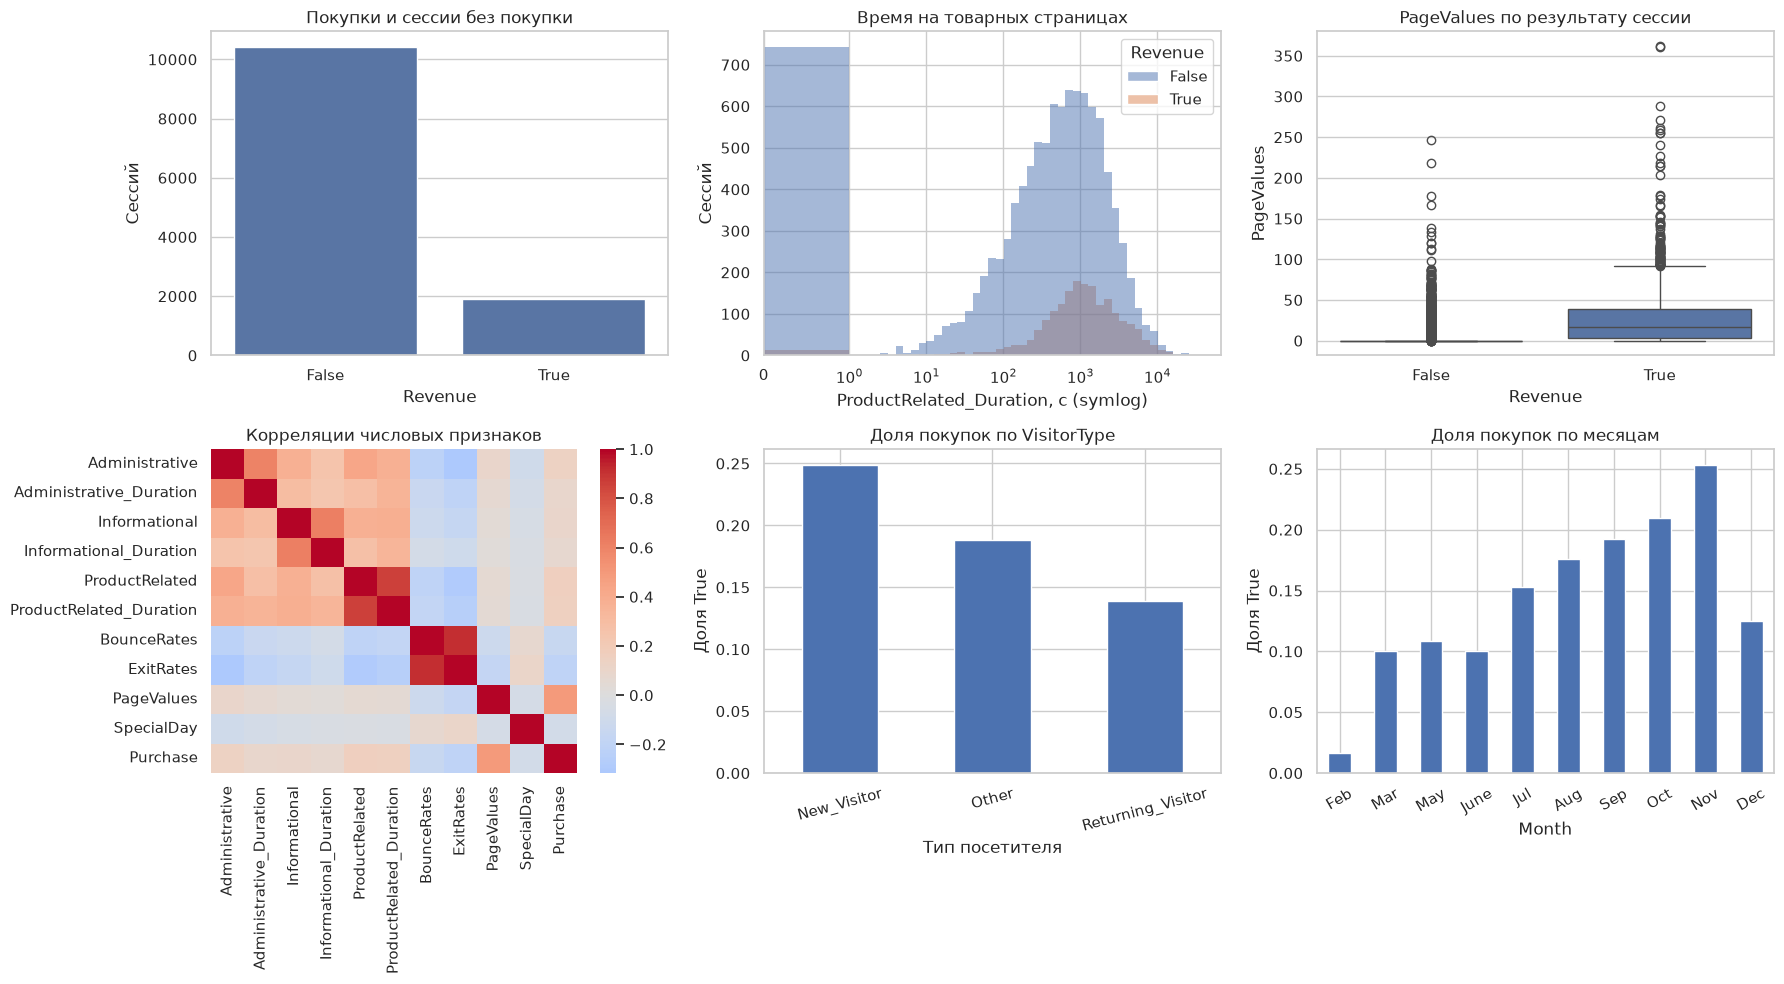

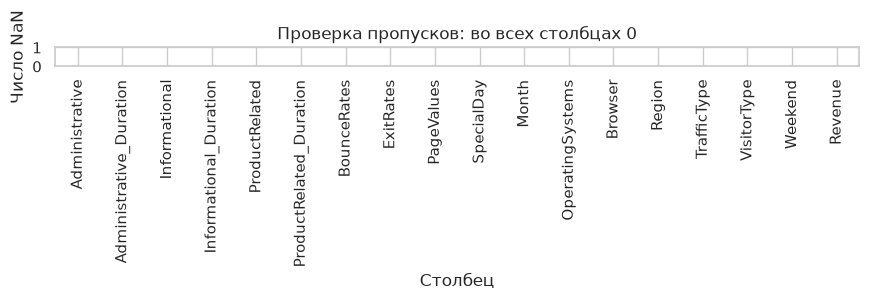

In [22]:
# Осматриваем типы и распределения исходных измерений.
df.info()  # Типы и заполненность.
print(df.describe(include='all').to_string())  # Числа и категории.
print('Пропуски:', df.isna().sum().to_dict())  # Полная проверка NaN.
print('Повторяющиеся строки:', int(df.duplicated().sum()))  # Диагностика.
eda = df.copy()  # Сохраняем исходный размер для EDA.
eda['Purchase'] = eda.Revenue.astype(int)  # Доля покупки в группе.
months = {'Jan':1,'Feb':2,'Mar':3,'Apr':4,'May':5,'June':6,'Jun':6,'Jul':7,'Aug':8,'Sep':9,'Oct':10,'Nov':11,'Dec':12}  # Календарь.
numeric = ['Administrative','Administrative_Duration','Informational','Informational_Duration','ProductRelated','ProductRelated_Duration','BounceRates','ExitRates','PageValues','SpecialDay']  # Числа.

# Шесть требуемых графиков с подписями.
fig, axes = plt.subplots(2, 3, figsize=(18, 10))  # Сетка.
sns.countplot(data=eda, x='Revenue', ax=axes[0,0])  # Классы.
axes[0,0].set(title='Покупки и сессии без покупки', xlabel='Revenue', ylabel='Сессий')  # Оси.
sns.histplot(data=eda, x='ProductRelated_Duration', hue='Revenue', bins=np.r_[0,np.geomspace(1,eda.ProductRelated_Duration.max(),49)], ax=axes[0,1])  # Время.
axes[0,1].set_xscale('symlog',linthresh=1)  # Показываем нули и длинный хвост без удаления строк.
axes[0,1].set_xlim(0, float(eda.ProductRelated_Duration.max())*1.05)  # Отрицательных длительностей нет.
axes[0,1].set(title='Время на товарных страницах', xlabel='ProductRelated_Duration, с (symlog)', ylabel='Сессий')  # Оси.
sns.boxplot(data=eda, x='Revenue', y='PageValues', ax=axes[0,2])  # Ценность.
axes[0,2].set(title='PageValues по результату сессии', xlabel='Revenue', ylabel='PageValues')  # Оси.
sns.heatmap(eda[numeric+['Purchase']].corr(), cmap='coolwarm', center=0, ax=axes[1,0])  # Связи.
axes[1,0].set_title('Корреляции числовых признаков')  # Название.
eda.groupby('VisitorType').Purchase.mean().plot.bar(ax=axes[1,1], rot=15)  # Тип посетителя.
axes[1,1].set(title='Доля покупок по VisitorType', xlabel='Тип посетителя', ylabel='Доля True')  # Оси.
month_order = sorted(eda.Month.unique(), key=lambda value: months[value])  # Календарный порядок.
eda.groupby('Month').Purchase.mean().reindex(month_order).plot.bar(ax=axes[1,2], rot=30)  # Месяцы.
axes[1,2].set(title='Доля покупок по месяцам', xlabel='Month', ylabel='Доля True')  # Оси.
fig.tight_layout()  # Защита подписей.
fig.savefig(EXAMPLES/'eda_plots.png', dpi=140, bbox_inches='tight')  # Артефакт.
plt.show()  # Рисунок в ноутбуке.

# Визуализируем нулевые количества пропусков, не выдумывая NaN.
fig, ax = plt.subplots(figsize=(9,3))  # Компактный график.
df.isna().sum().plot.bar(ax=ax)  # Число NaN по всем полям.
ax.set(title='Проверка пропусков: во всех столбцах 0', xlabel='Столбец', ylabel='Число NaN', ylim=(0,1))  # Оси.
fig.tight_layout()  # Поля.
fig.savefig(EXAMPLES/'missing_values.png', dpi=140)  # Сохранение.
plt.show()  # Вывод.

## Выводы по EDA

Доля покупок у новых посетителей — **24.91%**, у возвращающихся — **13.93%**. Это фактическая статистика: она не совпадает с примерным предположением из шаблона задания. В ноябре доля **25.35%**, в феврале **1.63%**, но объёмы групп различны. У покупающих сессий PageValues чаще положителен, у сессий без покупки много нулей. На оси длительности используется symlog: нули сохранены, длинный хвост не обрезается.

Пропусков нет, поэтому в текущих данных фактическая импутация не нужна. Длительности имеют длинный правый хвост, а числовые площади страницы и время связаны. Корреляции и доли групп описывают ассоциации, а не эффект изменения поведения пользователя.

In [13]:
# Удаляем только полные повторы, затем делим с сохранением классов.
clean_df = df.drop_duplicates().copy()  # Прозрачное правило очистки.
y = clean_df.Revenue.astype(int)  # Покупка равна единице.
raw_train, raw_test, y_train, y_test = train_test_split(clean_df.drop(columns='Revenue'), y,
    test_size=0.2, random_state=SEED, stratify=y)  # Отложенная выборка.
CAT_COLS = ['Month','OperatingSystems','Browser','Region','TrafficType','VisitorType','Weekend']  # Смысловые категории.

# Создаём все восемь обязательных и два циклических признака.
def engineer_sessions(raw):
    x = raw.drop(columns='Revenue', errors='ignore').copy()  # Исключаем цель.
    x['TotalPages'] = x.Administrative+x.Informational+x.ProductRelated  # Общие страницы.
    x['TotalDuration'] = x.Administrative_Duration+x.Informational_Duration+x.ProductRelated_Duration  # Время.
    x['AvgPageValue'] = x.PageValues/(x.TotalPages+1)  # Ценность на объём.
    x['BounceExitRatio'] = x.BounceRates/(x.ExitRates+0.001)  # Защищённое отношение.
    x['IsNewVisitor'] = x.VisitorType.eq('New_Visitor').astype(int)  # Новый посетитель.
    x['IsWeekend'] = x.Weekend.astype(int)  # Выходной.
    x['MonthNum'] = x.Month.map(months)  # Календарный словарь.
    if x.MonthNum.isna().any(): raise ValueError('Неизвестное название месяца')  # Не скрываем ошибку.
    x['IsHighTraffic'] = x.TrafficType.gt(10).astype(int)  # Группа кодов по условию.
    x['MonthSin'] = np.sin(2*np.pi*x.MonthNum/12)  # Цикл.
    x['MonthCos'] = np.cos(2*np.pi*x.MonthNum/12)  # Вторая координата цикла.
    return x  # Возвращаем расширенный набор.

# Обучаем One-Hot и резервные медианы исключительно на обучающей части.
def fit_preprocessing(raw, use_engineering=True, exclude_value=False):
    x = engineer_sessions(raw) if use_engineering else raw.copy()  # Вариант сравнения.
    if exclude_value: x = x.drop(columns=['PageValues','AvgPageValue'], errors='ignore')  # Проверка чувствительности.
    num_cols = [c for c in x if c not in CAT_COLS]  # Числа отдельно от категорий.
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(x[CAT_COLS].astype(str))  # Только train.
    columns = num_cols+list(encoder.get_feature_names_out(CAT_COLS))  # Порядок колонок.
    prep = {'use_engineering':use_engineering,'exclude_value':exclude_value,'num_cols':num_cols,
            'medians':{c:float(x[c].median()) for c in num_cols},'feature_cols':columns}  # JSON-параметры.
    return prep, encoder  # Состояние для инференса.

# Используем сохранённое состояние для теста и новых сессий.
def transform_sessions(raw, prep, encoder):
    x = engineer_sessions(raw) if prep['use_engineering'] else raw.copy()  # Те же формулы.
    numeric_part = x[prep['num_cols']].fillna(prep['medians']).astype(float)  # Резервная импутация.
    categorical = pd.DataFrame(encoder.transform(x[CAT_COLS].astype(str)), index=x.index,
        columns=encoder.get_feature_names_out(CAT_COLS))  # Без обучения на test.
    return pd.concat([numeric_part,categorical],axis=1).reindex(columns=prep['feature_cols']).astype(float)  # Порядок.

# Матрицы и scaler подготовлены без утечки из теста.
preprocessor, encoder = fit_preprocessing(raw_train)  # Fit только train.
X_train = transform_sessions(raw_train, preprocessor, encoder)  # Обучающие признаки.
X_test = transform_sessions(raw_test, preprocessor, encoder)  # Отложенные признаки.
feature_cols = list(X_train.columns)  # Порядок.
scaler = StandardScaler().fit(X_train)  # Сохраняется по заданию; деревья используют исходный масштаб.
assert not X_train.isna().any().any() and not X_test.isna().any().any()  # Полнота.
assert not set(map(tuple,raw_train.to_numpy())).intersection(map(tuple,raw_test.to_numpy()))  # Нет точных копий между частями.
print('Исходных/после удаления повторов:', len(df),len(clean_df))  # Размер.
print('Классы после очистки:', clean_df.Revenue.value_counts().to_dict())  # Пропорции.
print('Train/test:', X_train.shape,X_test.shape, 'доли покупок:',y_train.mean(),y_test.mean())  # Проверка.
print(engineer_sessions(raw_train)[['TotalPages','TotalDuration','AvgPageValue','BounceExitRatio','IsNewVisitor','IsWeekend','MonthNum','IsHighTraffic']].head().to_string())  # Восемь формул.

Исходных/после удаления повторов: 12330 12205
Классы после очистки: {False: 10297, True: 1908}
Train/test: (9764, 84) (2441, 84) доли покупок: 0.15628840639082342 0.15649324047521507
       TotalPages  TotalDuration  AvgPageValue  BounceExitRatio  IsNewVisitor  IsWeekend  MonthNum  IsHighTraffic
7556           51    1256.000000      0.718409              0.0             0          0        11              0
11924          30     901.288889      1.101562              0.0             1          0        12              0
3306           13     421.166667      0.000000              0.0             0          0         5              0
207             7     598.500000      0.000000              0.0             1          1         3              0
4460           16    1599.266667      0.000000              0.0             0          0         5              1


## Итог подготовки данных

Из 12330 строк удалены **125 полных повторов**, осталось **12205**. Разбиение: **9764 train / 2441 test**, с сохранением долей классов. One-Hot и числовые признаки образовали **84 столбца**, без NaN. Непересечение точных исходных строк между train и test проверено кодом.

Все восемь обязательных формул реализованы; дополнительно созданы две координаты годового цикла. Технические коды обрабатываются как категории. Scaler обучен по требуемой структуре артефактов, но модели деревьев и их инференс используют немасштабированные признаки.

## 6. Построение и обучение моделей

Random Forest представляет bagging и уменьшает чувствительность отдельных деревьев. XGBoost добавляет регуляризованный boosting, LightGBM сравнивает гистограммное построение, CatBoost — другую реализацию бустинга. У всех одна матрица One-Hot; нативная работа CatBoost с категориями отдельно не тестируется. Дисбаланс компенсируется весами, а scale_pos_weight XGBoost рассчитывается по train. Время измеряется вокруг fit.

In [14]:
# Четыре модели используют одинаковые признаки и фиксированный seed.
class_ratio = float((y_train == 0).sum() / (y_train == 1).sum())  # Баланс только по train
models = {
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=10,  # Bagging с весами
        class_weight='balanced', random_state=SEED, n_jobs=2),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,  # Взвешенный бустинг
        subsample=0.9, colsample_bytree=0.9, scale_pos_weight=class_ratio,
        random_state=SEED, eval_metric='logloss', n_jobs=2),
    'LightGBM': LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7,  # Гистограммный бустинг
        learning_rate=0.05, class_weight='balanced', random_state=SEED,
        verbosity=-1, n_jobs=2, importance_type='gain'),
    'CatBoost': CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1,  # Балансировка классов
        auto_class_weights='Balanced', random_seed=SEED, verbose=False,
        thread_count=2, allow_writing_files=False)
}

# Фиксируем реальное время каждого обучения.
fit_times = {}
for name, model in models.items():
    started = time.perf_counter()  # Измеряем время
    model.fit(X_train, y_train)  # Обучаем на train
    fit_times[name] = time.perf_counter() - started  # Длительность fit
    print(f'{name}: {fit_times[name]:.3f} сек')

Random Forest: 1.798 сек


XGBoost: 0.765 сек


LightGBM: 0.305 сек


CatBoost: 2.060 сек


## Параметры и время обучения

| Модель | Тип | Параметры | Время fit, с |
|---|---|---|---:|
| Random Forest | Bagging | 200 деревьев, глубина 10, balanced | 1.621 |
| XGBoost | Boosting | 200 деревьев, глубина 6, scale_pos_weight по train | 0.717 |
| LightGBM | Boosting | 200 деревьев, 31 лист, глубина 7, balanced | 0.396 |
| CatBoost | Boosting | 200 итераций, глубина 6, Balanced | 2.135 |

Время исключает подготовку данных и EDA. Показанное сравнение относится к одинаковой выборке и оборудованию этого запуска.

Замеры в таблице относятся к последнему полному прогону приложения. Отдельные ячейки также сохраняют свой выполненный пошаговый запуск; длительности зависят от текущей нагрузки.

## 7. Оценка качества

Сравниваем Accuracy, Precision, Recall, F1 и ROC-AUC при положительном классе «покупка» и пороге 0,5. ROC-AUC рассчитывается по вероятностям. Матрица ошибок ниже относится к лидеру исходных четырёх моделей; дальнейшая настройка LightGBM не использует тест в objective.

               accuracy  precision  recall      f1  roc_auc
Random Forest    0.8726     0.5617  0.8455  0.6750   0.9332
XGBoost          0.8791     0.5893  0.7513  0.6605   0.9300
LightGBM         0.8714     0.5632  0.7932  0.6587   0.9321
CatBoost         0.8734     0.5662  0.8168  0.6688   0.9328
Лидер исходного сравнения: Random Forest
Accuracy постоянного No: 0.8435067595247849


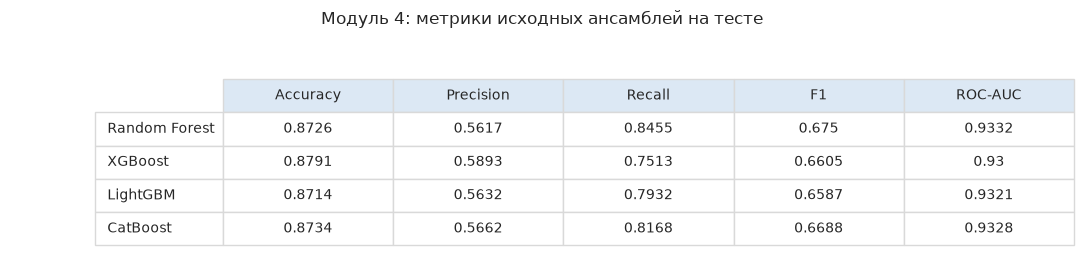

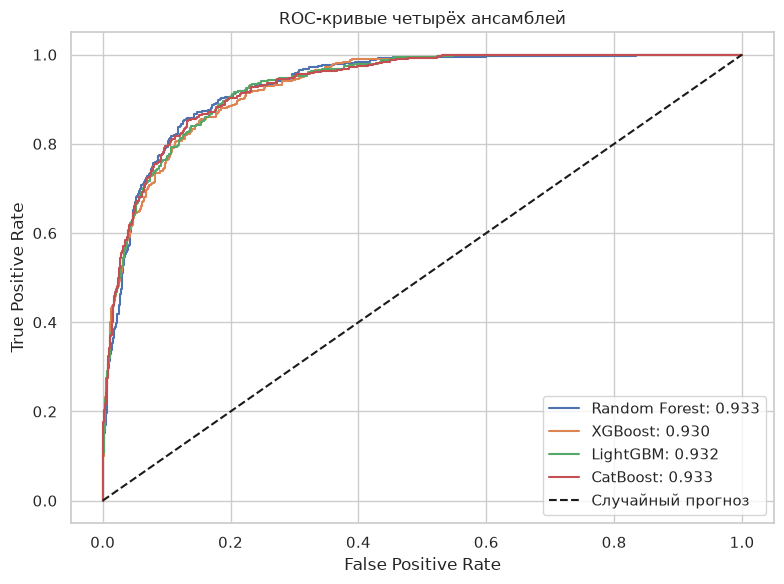

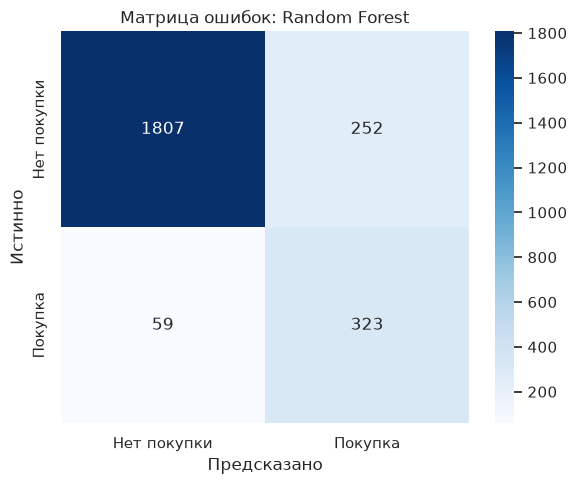

In [15]:
# Единая функция обеспечивает сопоставимость всех метрик.
def evaluate(model, x, target):
    proba = model.predict_proba(x)[:, 1]  # Риск положительного класса
    pred = (proba >= 0.5).astype(int)  # Общий порог
    return {'accuracy': float(accuracy_score(target, pred)),
            'precision': float(precision_score(target, pred, zero_division=0)),  # Точность среди предсказанных покупок
            'recall': float(recall_score(target, pred, zero_division=0)),  # Доля найденных покупок
            'f1': float(f1_score(target, pred, zero_division=0)),  # Баланс Precision и Recall
            'roc_auc': float(roc_auc_score(target, proba))}  # Ранжирование по вероятностям

# Отложенные метрики не используются для настройки параметров.
baseline_metrics = {name: evaluate(model, X_test, y_test) for name, model in models.items()}  # Единая тестовая оценка
results_df = pd.DataFrame(baseline_metrics).T  # Таблица метрик
baseline_winner = results_df.roc_auc.idxmax()  # Лидер baseline
print(results_df.round(4).to_string())
print('Лидер исходного сравнения:', baseline_winner)
print('Accuracy постоянного No:', float((y_test == 0).mean()))


# Сохраняем таблицу метрик отдельным изображением для приложения к сдаче.
fig,ax = plt.subplots(figsize=(11,2.8))
ax.axis('off')  # Таблица без координатных осей.
display_table = results_df.rename(columns={'accuracy':'Accuracy','precision':'Precision','recall':'Recall','f1':'F1','roc_auc':'ROC-AUC'})
tab = ax.table(cellText=display_table.round(4).values,rowLabels=display_table.index,colLabels=display_table.columns,
               cellLoc='center',loc='center',bbox=[0.20,0.04,0.80,0.78])  # Те же значения, что в коде.
tab.auto_set_font_size(False)
tab.set_fontsize(10)  # Читаемые числа.
for (row,col),cell in tab.get_celld().items():
    cell.set_edgecolor('#D9D9D9')  # Видимые границы.
    if row==0:
        cell.set_facecolor('#DCE8F4')  # Заголовок.
ax.set_title('Модуль 4: метрики исходных ансамблей на тесте',pad=12)
fig.tight_layout()  # Не обрезаем названия.
fig.savefig(EXAMPLES/'metrics_table.png',dpi=160,bbox_inches='tight')
plt.show()  # Таблица видна и в ноутбуке.

# Сравниваем четыре ROC-кривые на общей шкале.
fig, ax = plt.subplots(figsize=(8, 6))  # Отдельный рисунок
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])  # ROC по вероятностям
    ax.plot(fpr, tpr, label=f"{name}: {baseline_metrics[name]['roc_auc']:.3f}")  # Рисуем кривую
ax.plot([0, 1], [0, 1], 'k--', label='Случайный прогноз')  # Рисуем кривую
ax.set(title='ROC-кривые четырёх ансамблей', xlabel='False Positive Rate', ylabel='True Positive Rate')  # Названия осей
ax.legend(loc='lower right')  # Подписываем модели
fig.tight_layout()  # Защита от наложений
fig.savefig(EXAMPLES / 'roc_curves.png', dpi=140)  # Сохраняем артефакт
plt.show()  # Показываем график

# Матрица показывает пропущенные уходы и ложные тревоги.
winner_pred = (models[baseline_winner].predict_proba(X_test)[:, 1] >= 0.5).astype(int)  # Порог 0,5
baseline_cm = confusion_matrix(y_test, winner_pred)  # TN, FP, FN, TP
fig, ax = plt.subplots(figsize=(6, 5))  # Отдельный рисунок
sns.heatmap(baseline_cm, annot=True, fmt='d', cmap='Blues', ax=ax,
    xticklabels=['Нет покупки', 'Покупка'], yticklabels=['Нет покупки', 'Покупка'])
ax.set(title=f'Матрица ошибок: {baseline_winner}', xlabel='Предсказано', ylabel='Истинно')  # Названия осей
fig.tight_layout()  # Защита от наложений
fig.savefig(EXAMPLES / 'confusion_matrix.png', dpi=140)  # Сохраняем артефакт
plt.show()  # Показываем график

## Результаты и анализ ошибок

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Random Forest | 0.8726 | 0.5617 | 0.8455 | 0.6750 | 0.9332 |
| XGBoost | 0.8791 | 0.5893 | 0.7513 | 0.6605 | 0.9300 |
| LightGBM | 0.8714 | 0.5632 | 0.7932 | 0.6587 | 0.9321 |
| CatBoost | 0.8734 | 0.5662 | 0.8168 | 0.6688 | 0.9328 |

Лидер исходного сравнения по тестовому ROC-AUC — **Random Forest**, **0.9332**. Его матрица: **1807** верных «нет покупки», **323** найденных покупок, **252** ложных сигналов и **59** пропущенных покупок. Самая быстрая базовая модель — **LightGBM**. Изображение этой таблицы сохранено как examples/metrics_table.png.

Высокая Accuracy не означает обнаружение большинства покупателей. Увеличение Recall ценой Precision создаёт больше ложных сигналов; рабочий порог не настраивается по этому тесту.

## 8. Интерпретация и бизнес-инсайты

Сравниваем важности Random Forest и LightGBM на отдельных шкалах: impurity и gain. Затем проверяем полезность Feature Engineering на пяти одинаковых train CV-блоках: исходные признаки, расширенные признаки и расширенные без PageValues/AvgPageValue. Кодировщик каждого блока обучается на его обучающих строках. Важности не устанавливают причинность, а сравнение без транзакционной ценности — проверка чувствительности.

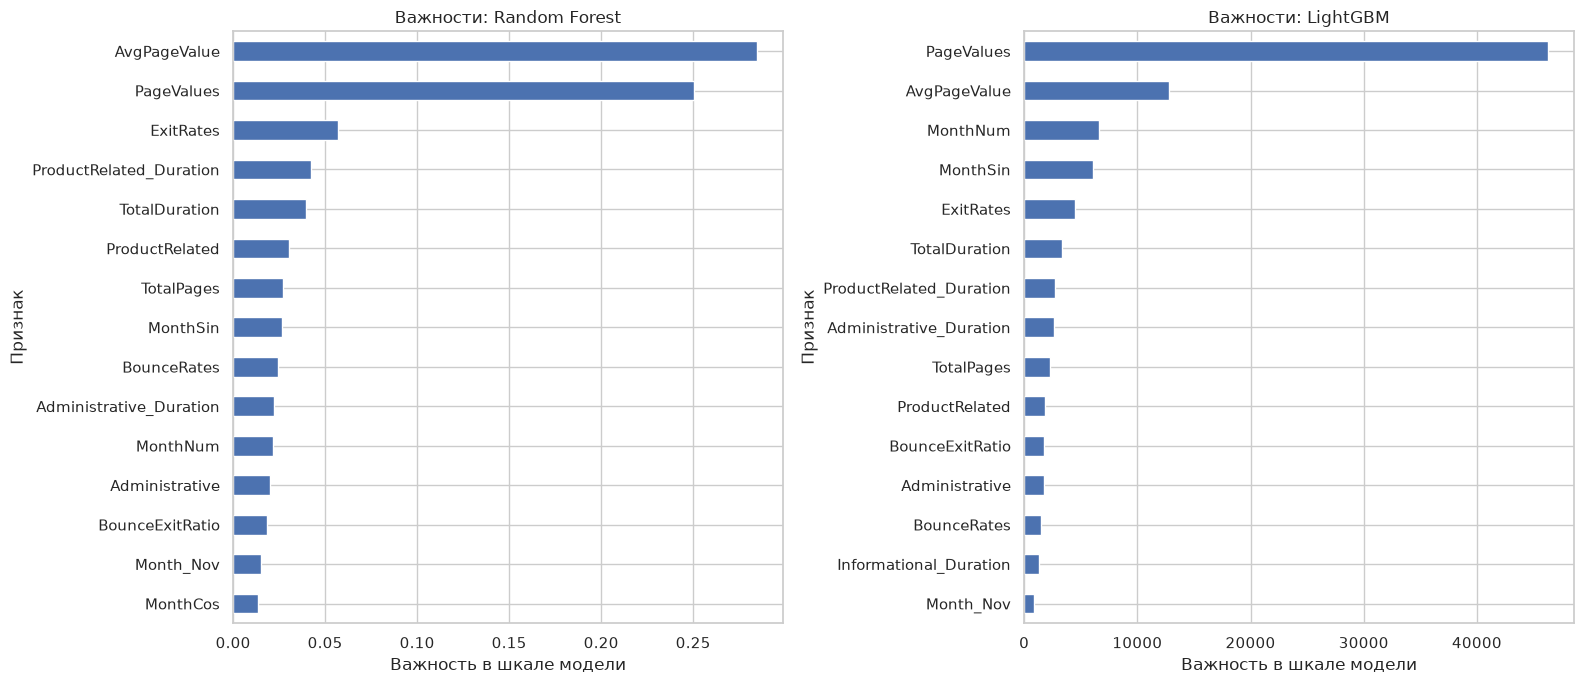

Посетители: {'mean': {'New_Visitor': 0.24911452184179456, 'Other': 0.18823529411764706, 'Returning_Visitor': 0.1393232868922377}, 'count': {'New_Visitor': 1694, 'Other': 85, 'Returning_Visitor': 10551}}
Месяцы: {'mean': {'Feb': 0.016304347826086956, 'Mar': 0.10068169900367069, 'May': 0.10850178359096314, 'June': 0.10069444444444445, 'Jul': 0.1527777777777778, 'Aug': 0.17551963048498845, 'Sep': 0.19196428571428573, 'Oct': 0.20947176684881602, 'Nov': 0.25350233488992663, 'Dec': 0.1250723798494499}, 'count': {'Feb': 184, 'Mar': 1907, 'May': 3364, 'June': 288, 'Jul': 432, 'Aug': 433, 'Sep': 448, 'Oct': 549, 'Nov': 2998, 'Dec': 1727}}
Топ-5 gain: {'PageValues': 46262.32089078761, 'AvgPageValue': 12835.452844581829, 'MonthNum': 6626.065413955638, 'MonthSin': 6065.971120179485, 'ExitRates': 4533.544330976031}


Feature Engineering CV: {
  "Original": {
    "mean": 0.9267753194507533,
    "std": 0.006597789820739376,
    "fold_scores": [
      0.9221440448269977,
      0.9194890975648575,
      0.9282667515518065,
      0.9385663695686773,
      0.9254103337414276
    ]
  },
  "Engineered": {
    "mean": 0.926886071120145,
    "std": 0.006670806471975471,
    "fold_scores": [
      0.923935775484045,
      0.9178000159159636,
      0.9265438484800255,
      0.9382957981855802,
      0.9278549175351111
    ]
  },
  "WithoutPageValues": {
    "mean": 0.7723829075978996,
    "std": 0.013287657260406769,
    "fold_scores": [
      0.7671246195300627,
      0.7556839885405061,
      0.7957623746617858,
      0.7754595734521725,
      0.7678839818049707
    ]
  }
}


In [16]:
# Важности разных алгоритмов не сравниваются в абсолютных единицах.
importance_tables = {name:pd.Series(models[name].feature_importances_,index=feature_cols).sort_values(ascending=False)
    for name in ['Random Forest','LightGBM']}  # Отдельные шкалы.
fig, axes = plt.subplots(1,2,figsize=(16,7))  # Два алгоритма.
for ax,(name,values) in zip(axes,importance_tables.items()):
    values.head(15).sort_values().plot.barh(ax=ax)  # Топ-15.
    ax.set(title=f'Важности: {name}',xlabel='Важность в шкале модели',ylabel='Признак')  # Оси.
fig.tight_layout()  # Поля.
fig.savefig(EXAMPLES/'feature_importance.png',dpi=140)  # Артефакт.
plt.show()  # Вывод.

# Наблюдаемые доли покупки для бизнес-интерпретации.
visitor_rates = eda.groupby('VisitorType').Purchase.agg(['mean','count'])  # Типы посетителей.
month_rates = eda.groupby('Month').Purchase.agg(['mean','count']).reindex(month_order)  # Месяцы.
print('Посетители:',visitor_rates.to_dict())  # Доли и размеры.
print('Месяцы:',month_rates.to_dict())  # Сезонность.
print('Топ-5 gain:',importance_tables['LightGBM'].head(5).to_dict())  # Важности.

# Контролируемое сравнение только на train, без настройки по test.
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)  # Общие блоки.
cv_indices = list(cv.split(raw_train,y_train))  # Один и тот же набор разбиений.
def make_cv_data(use_engineering=True,exclude_value=False):
    folds=[]  # Матрицы блоков.
    for fit_ids,val_ids in cv_indices:
        fit_raw,val_raw=raw_train.iloc[fit_ids],raw_train.iloc[val_ids]  # Сырые строки.
        prep,enc=fit_preprocessing(fit_raw,use_engineering,exclude_value)  # Только CV-train.
        folds.append((transform_sessions(fit_raw,prep,enc),y_train.iloc[fit_ids],
                      transform_sessions(val_raw,prep,enc),y_train.iloc[val_ids]))  # Сохраняем блок.
    return folds  # Общая структура для сравнения.

# Одни гиперпараметры baseline применяются ко всем представлениям.
fixed_lgbm = dict(class_weight='balanced',random_state=SEED,verbosity=-1,n_jobs=2,importance_type='gain')  # Фиксировано.
baseline_params = dict(n_estimators=200,num_leaves=31,max_depth=7,learning_rate=0.05)  # По заданию.
def score_folds(params,folds):
    scores=[]  # AUC блоков.
    for xf,yf,xv,yv in folds:
        estimator=LGBMClassifier(**params,**fixed_lgbm).fit(xf,yf)  # Fit CV-train.
        scores.append(roc_auc_score(yv,estimator.predict_proba(xv)[:,1]))  # AUC CV-validation.
    return scores  # Сохраняем распределение оценок.

cv_data = make_cv_data()  # Расширенные признаки для последующего Optuna.
feature_experiment = {}  # Результаты трёх режимов.
for label,folds in [('Original',make_cv_data(False)),('Engineered',cv_data),('WithoutPageValues',make_cv_data(True,True))]:
    scores=score_folds(baseline_params,folds)  # Контролируем только представление.
    feature_experiment[label]={'mean':float(np.mean(scores)),'std':float(np.std(scores)),'fold_scores':list(map(float,scores))}  # CV.
print('Feature Engineering CV:',json.dumps(feature_experiment,indent=2))  # Измеренный эффект.

## Бизнес-инсайты и эффект новых признаков

Топ-5 gain-важностей LightGBM: **PageValues, AvgPageValue, MonthNum, MonthSin, ExitRates**. У новых посетителей покупка наблюдается в **24.91%** случаев, у возвращающихся — в **13.93%**. Это основание исследовать качество привлечения и различия сессий, а не автоматически считать возвращающихся лучшим сегментом. Ноябрьская доля **25.35%** согласуется с сезонностью, но без точных дат и повторных лет эффект не отделён от состава трафика.

| Представление | Средний train CV ROC-AUC | Std по 5 блокам |
|---|---:|---:|
| Исходные 17 признаков | 0.926775 | 0.006598 |
| С производными признаками | 0.926886 | 0.006671 |
| Без PageValues и AvgPageValue | 0.772383 | 0.013288 |

Изменение от создания признаков — **+0.000111 ROC-AUC**, существенно меньше разброса блоков. Убедительного выигрыша именно от Feature Engineering на этом сравнении не показано. После исключения PageValues и AvgPageValue CV ROC-AUC составляет **0.7724**: качество сильно зависит от этих транзакционных агрегатов. Это проверка чувствительности, а не доказательство утечки в исходном наборе.

Трафик с кодом больше 10 не обязан быть интенсивным: это условное разбиение категорий из задания. Из наблюдаемых долей нельзя заключать, что изменение признака само по себе вызывает покупку.

## 9. Тюнинг гиперпараметров (Optuna)

Настраиваем LightGBM по пошаговому заданию: TPE с seed=42, 30 испытаний, средний ROC-AUC пяти стратифицированных блоков train. В каждом блоке заново обучается One-Hot и оцениваются резервные медианы. Подбираются деревья, листья, глубина, темп, подвыборки и L1/L2. subsample_freq=1 включает реальную подвыборку строк. Время поиска отделено от финального fit.

In [17]:
import optuna  # Поиск гиперпараметров
optuna.logging.set_verbosity(optuna.logging.WARNING)
# Одни настройки воспроизводимости применяются ко всем trial.
fixed_lgbm = dict(class_weight='balanced', random_state=SEED, verbosity=-1, n_jobs=2, importance_type='gain')  # Общие параметры
def cv_auc(params):
    scores = []  # Оценки блоков
    for x_fit, y_fit, x_val, y_val in cv_data:
        candidate = LGBMClassifier(**params, **fixed_lgbm).fit(x_fit, y_fit)  # Fit на CV-train
        scores.append(roc_auc_score(y_val, candidate.predict_proba(x_val)[:, 1]))  # AUC на CV-validation
    return float(np.mean(scores))

# Baseline оценивается на тех же пяти блоках.
baseline_params = dict(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05)  # Исходный LightGBM
baseline_cv_auc = cv_auc(baseline_params)  # Те же CV-блоки
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),  # Число деревьев
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),  # Максимум листьев
        'max_depth': trial.suggest_int('max_depth', 3, 12),  # Глубина
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),  # Темп
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),  # Доля строк
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),  # Доля признаков
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),  # Минимум строк в листе
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),  # L1
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),  # L2
        'subsample_freq': 1}  # Включаем подвыборку
    return cv_auc(params)

# TPE использует результаты train CV и фиксированный seed.
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))  # TPE с seed
started = time.perf_counter()  # Измеряем время
study.optimize(objective, n_trials=30, n_jobs=1, show_progress_bar=False)  # 30 испытаний train CV
search_time = time.perf_counter() - started  # Время поиска
best_params = {**study.best_params, 'subsample_freq': 1}  # Выигравший trial
best_model = LGBMClassifier(**best_params, **fixed_lgbm)  # Финальный LightGBM
started = time.perf_counter()  # Измеряем время
best_model.fit(X_train, y_train)  # Весь train
tuned_fit_time = time.perf_counter() - started  # Время финального fit
tuned_metrics = evaluate(best_model, X_test, y_test)  # Отложенная оценка

# Разделяем train CV и единую тестовую оценку.
print('Trials:', len(study.trials), 'CV baseline:', baseline_cv_auc, 'CV Optuna:', study.best_value)
print('Test baseline:', baseline_metrics['LightGBM']['roc_auc'], 'Test Optuna:', tuned_metrics['roc_auc'])
print('Search seconds:', search_time, 'Final fit seconds:', tuned_fit_time)
print('Best parameters:', json.dumps(best_params, indent=2))
print('Метрики Optuna:', tuned_metrics)
study.trials_dataframe().to_csv(MODELS / 'optuna_trials.csv', index=False)  # Полная история

C:\Users\lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Trials: 30 CV baseline: 0.926886071120145 CV Optuna: 0.9351712753763991
Test baseline: 0.9321342389051769 Test Optuna: 0.9365046571176472
Search seconds: 55.112838699998974 Final fit seconds: 0.3367078999981459
Best parameters: {
  "n_estimators": 200,
  "num_leaves": 30,
  "max_depth": 6,
  "learning_rate": 0.010625520240503112,
  "subsample": 0.8427691130411582,
  "colsample_bytree": 0.9312446855299032,
  "min_child_samples": 42,
  "reg_alpha": 0.813162965787202,
  "reg_lambda": 0.13700169099277154,
  "subsample_freq": 1
}
Метрики Optuna: {'accuracy': 0.8664481769766489, 'precision': 0.5469798657718121, 'recall': 0.8534031413612565, 'f1': 0.6666666666666666, 'roc_auc': 0.9365046571176472}


## Результаты Optuna

Проведены **30 испытаний**. Train CV ROC-AUC: **0.9269 → 0.9352**. Тест: **0.9321 → 0.9365**. Разница **+0.0044**, или **+0.44 процентного пункта**. Поиск занял **54.90 с**, итоговый fit — **0.361 с**.

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| LightGBM baseline | 0.8714 | 0.5632 | 0.7932 | 0.6587 | 0.9321 |
| LightGBM Optuna | 0.8664 | 0.5470 | 0.8534 | 0.6667 | 0.9365 |

**Параметры лучшего trial:**

- n_estimators: 200
- num_leaves: 30
- max_depth: 6
- learning_rate: 0.01062552
- subsample: 0.8427691
- colsample_bytree: 0.9312447
- min_child_samples: 42
- reg_alpha: 0.813163
- reg_lambda: 0.1370017
- subsample_freq: 1

Изменение ROC-AUC указывается в абсолютных единицах и процентных пунктах; CV и тест представлены отдельно. Различие на одном тесте не подтверждает улучшение на всех будущих выборках.

## 10. Интерпретация через SHAP

Объясняем LightGBM после Optuna. Строим Summary, bar, waterfall для сессии с максимальной модельной вероятностью покупки и dependence для ведущего признака по mean(|SHAP|). Шкала — raw log-odds. Проверка аддитивности сопоставляет сумму вкладов с raw score для всех тестовых строк.

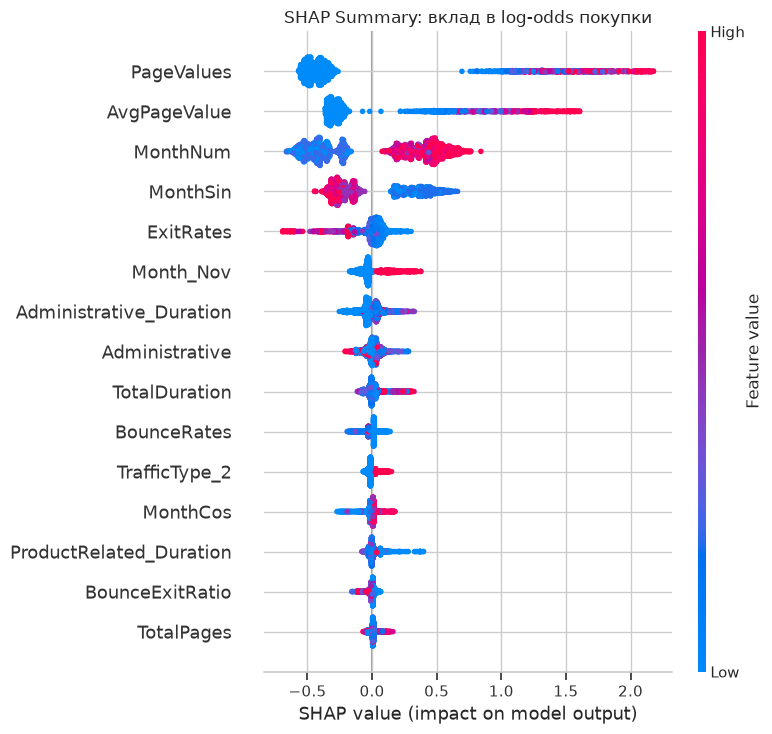

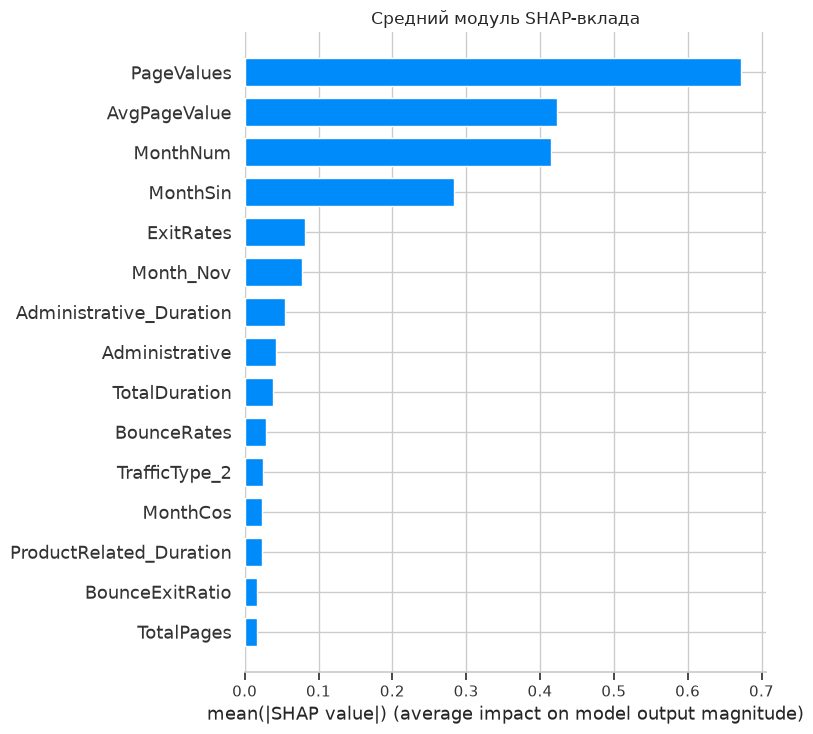

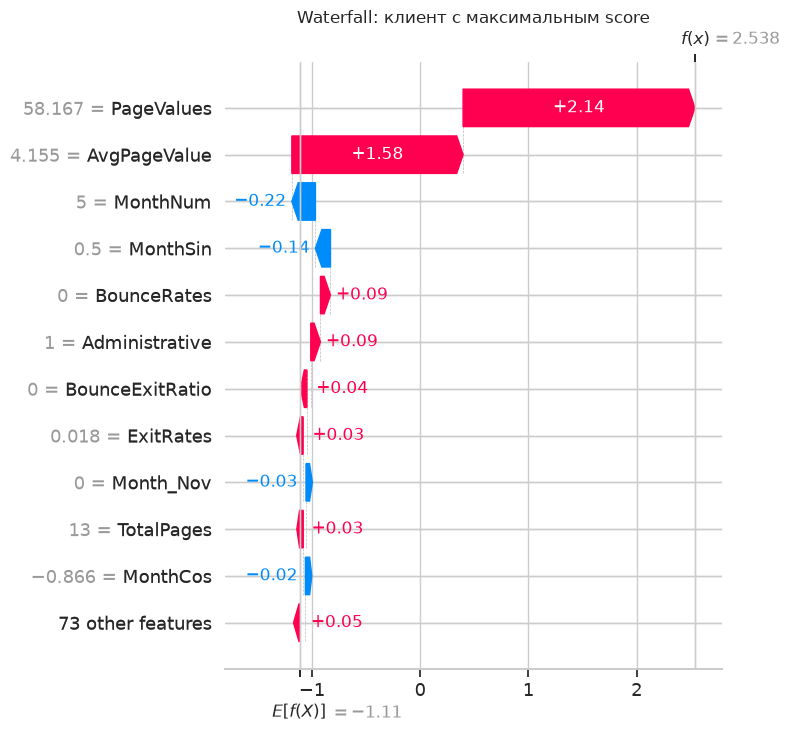

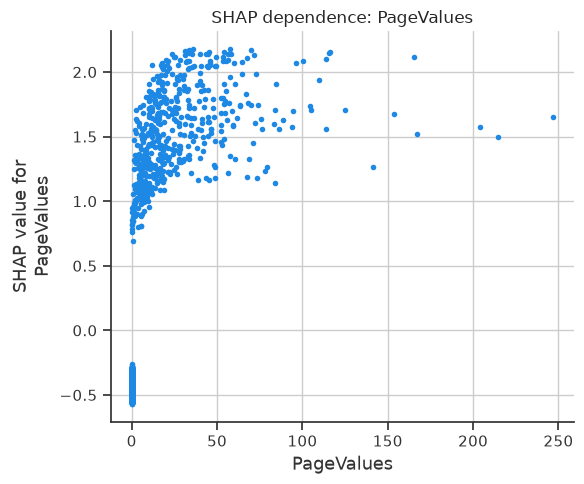

Топ SHAP: {'PageValues': 0.6727061430657791, 'AvgPageValue': 0.4227698962035738, 'MonthNum': 0.41424754901024075, 'MonthSin': 0.2828982082655887, 'ExitRates': 0.08230265452728597}
Сессия: 4865 модельный score покупки: 0.9267884012316291
Базовый raw score: -1.1100075942795486 Итоговый raw score: 2.5383714160893764
PageValues = 58.16727273 SHAP log-odds: 2.1415
AvgPageValue = 4.154805195 SHAP log-odds: 1.5818
MonthNum = 5.0 SHAP log-odds: -0.2181
MonthSin = 0.49999999999999994 SHAP log-odds: -0.1388
BounceRates = 0.0 SHAP log-odds: 0.0926


In [18]:
# Рассчитываем SHAP и учитываем возможные формы бинарного выхода.
import shap  # Подключаем shap
explainer = shap.TreeExplainer(best_model, model_output='raw')  # Шкала raw score
explanation = explainer(X_test)  # Все тестовые клиенты
shap_values = np.asarray(explanation.values)  # Значения Шепли
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]  # Значения Шепли
base_values = np.asarray(explanation.base_values)  # Базовый выход
if base_values.ndim == 2:
    base_values = base_values[:, 1]  # Базовый выход
base_values = np.broadcast_to(base_values, len(X_test))  # Базовый выход
raw_scores = best_model.predict(X_test, raw_score=True)  # Проверяем log-odds
assert np.allclose(base_values + shap_values.sum(axis=1), raw_scores, atol=1e-6)

# Summary и bar показывают глобальное распределение вкладов.
shap.summary_plot(shap_values, X_test, show=False, max_display=15)  # Глобальные вклады
plt.title('SHAP Summary: вклад в log-odds покупки')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_summary.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график
shap.summary_plot(shap_values, X_test, plot_type='bar', show=False, max_display=15)  # Глобальные вклады
plt.title('Средний модуль SHAP-вклада')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_bar.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график

# Waterfall объясняет сессию с максимальным модельным шансом покупки.
tuned_proba = best_model.predict_proba(X_test)[:, 1]  # Модельный score покупки
worst_idx = int(np.argmax(tuned_proba))  # Максимальный score покупки
local_explanation = shap.Explanation(values=shap_values[worst_idx], base_values=base_values[worst_idx],  # Объяснение одного сессию
    data=X_test.iloc[worst_idx].to_numpy(), feature_names=feature_cols)
shap.plots.waterfall(local_explanation, max_display=12, show=False)  # Локальные вклады
plt.title('Waterfall: сессия с максимальным score')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_waterfall.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график

# Dependence использует ведущий признак по среднему модулю SHAP.
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_cols).sort_values(ascending=False)  # Средний модуль вкладов
top_feature = str(shap_importance.index[0])  # Ведущий SHAP-признак
shap.dependence_plot(top_feature, shap_values, X_test, interaction_index=None, show=False)  # Вклад в зависимости от входа
plt.title(f'SHAP dependence: {top_feature}')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_dependence.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график

# Для локального случая печатаем исходные значения, а не только коды.
local_top = pd.Series(shap_values[worst_idx], index=feature_cols).sort_values(key=np.abs, ascending=False).head(5)  # Пять сильнейших вкладов
print('Топ SHAP:', shap_importance.head(5).to_dict())
print('Сессия:', str(raw_test.index[worst_idx]), 'модельный score покупки:', tuned_proba[worst_idx])
print('Базовый raw score:', base_values[worst_idx], 'Итоговый raw score:', raw_scores[worst_idx])
for field, contribution in local_top.items():
    raw_value = raw_test.iloc[worst_idx].get(field, X_test.iloc[worst_idx][field])  # Исходная категория
    print(field, '=', raw_value, 'SHAP log-odds:', round(contribution, 4))

## SHAP-интерпретация

Ведущие признаки по среднему модулю SHAP: **PageValues, AvgPageValue, MonthNum, MonthSin, ExitRates**. Dependence показывает **PageValues**. Для строки исходного CSV с индексом **4865** модель оценила вероятность покупки в **92.68%**. Это взвешенный модельный score, а не подтверждённая калиброванная вероятность.

| Признак | Значение для сессии | SHAP, log-odds |
|---|---|---:|
| PageValues | 58.16727273 | +2.1415 |
| AvgPageValue | 4.154805195 | +1.5818 |
| MonthNum | 5.0 | -0.2181 |
| MonthSin | 0.49999999999999994 | -0.1388 |
| BounceRates | 0.0 | +0.0926 |

В локальном объяснении PageValues и AvgPageValue дают самые сильные положительные вклады. Общая и нормированная ценность связаны, поэтому эти вклады нельзя читать как отдельные причинные эффекты. Аддитивность SHAP проверена по raw score всех тестовых сессий.

Положительные значения увеличивают логит покупки; перевод в вероятность нелинеен. Цвет One-Hot обозначает индикатор категории, а не её порядковый номер. Сходные производные признаки могут делить между собой вклад, поэтому нельзя читать их как независимые причины.

На Summary большие PageValues и AvgPageValue обычно соответствуют положительным вкладам, а высокие ExitRates — отрицательным. Это наблюдение о модели на имеющихся срезах. Сам по себе низкий показатель отказов не гарантирует покупку.

## 11. Сохранение модели

Сохраняются четыре исходные модели, лучший trial LightGBM, scaler, OneHotEncoder, параметры подготовки и порядок признаков. Метрики содержат отдельно test, CV, время обучения и поиска. Вместе с функциями из ноутбука подготовка исходных сессий воспроизводится без fit на новых данных.

In [19]:
# Сохраняем стандартные модели без пользовательских классов в pickle.
file_names={'Random Forest':'rf_model.pkl','XGBoost':'xgb_model.pkl','LightGBM':'lgbm_model.pkl','CatBoost':'cat_model.pkl'}  # Имена.
for name,filename in file_names.items():
    joblib.dump(models[name],MODELS/filename,compress=3)  # Базовые модели.
joblib.dump(best_model,MODELS/'best_model.pkl',compress=3)  # Выбранный CV trial.
joblib.dump(scaler,MODELS/'scaler.pkl',compress=3)  # По структуре задания.
joblib.dump(encoder,MODELS/'encoder.pkl',compress=3)  # Стандартный OneHotEncoder.
(MODELS/'feature_cols.json').write_text(json.dumps(feature_cols,ensure_ascii=False,indent=2),encoding='utf-8')  # Порядок.
(MODELS/'preprocessor.json').write_text(json.dumps(preprocessor,ensure_ascii=False,indent=2),encoding='utf-8')  # Медианы и режим.

# Версии и фактические метрики позволяют повторить эксперимент.
packages=['pandas','numpy','scikit-learn','xgboost','lightgbm','catboost','optuna','shap','matplotlib','seaborn','joblib','requests']  # Пакеты.
versions={p:version(p) for p in packages}  # Реальные версии.
metrics={'baseline':baseline_metrics,'fit_time_sec':fit_times,'tuned':tuned_metrics,'best_model':'LightGBM (Optuna)',
    'baseline_test_winner':baseline_winner,'cv_baseline_roc_auc':baseline_cv_auc,'cv_best_roc_auc':float(study.best_value),
    'best_params':best_params,'n_trials':len(study.trials),'cv_folds':5,'search_time_sec':search_time,
    'tuned_fit_time_sec':tuned_fit_time,'source_rows':len(df),'clean_rows':len(clean_df),'removed_duplicates':len(df)-len(clean_df),
    'train_rows':len(X_train),'test_rows':len(X_test),'feature_count':len(feature_cols),'seed':SEED,'threshold':0.5,
    'training_date':'2026-11-02','versions':versions,'feature_experiment':feature_experiment,
    'data_sha256':hashlib.sha256((DATA/'online_shoppers_intention.csv').read_bytes()).hexdigest()}  # Все условия.
(MODELS/'metrics.json').write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding='utf-8')  # Метаданные.
report={'metrics':metrics,'visitor_rates':visitor_rates.to_dict(),'month_rates':month_rates.to_dict(),
    'baseline_cm':baseline_cm.tolist(),'importance':importance_tables['LightGBM'].head(5).to_dict(),
    'shap_top':shap_importance.head(5).to_dict(),'shap_feature':top_feature,'best_session':int(raw_test.index[worst_idx]),
    'best_probability':float(tuned_proba[worst_idx]),
    'local_shap':{field:{'value':float(value),'raw_value':str(raw_test.iloc[worst_idx].get(field,X_test.iloc[worst_idx][field]))}
                  for field,value in local_top.items()}}  # Числа для Markdown.
(MODELS/'report_details.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')  # Проверяемые выводы.
print('Сохранены:',', '.join(sorted(p.name for p in MODELS.iterdir())))  # Список артефактов.

Сохранены: best_model.pkl, cat_model.pkl, encoder.pkl, feature_cols.json, lgbm_model.pkl, load_verification.json, metrics.json, optuna_trials.csv, preprocessor.json, report_details.json, rf_model.pkl, scaler.pkl, xgb_model.pkl


## Итог сохранения

Модели и подготовка записаны в models/. История всех trial находится в optuna_trials.csv; feature_experiment в metrics.json содержит распределения CV-оценок до и после создания признаков. Далее проверяется восстановление прогнозов.

## 12. Загрузка модели из репозитория

Проверяем локальную десериализацию, затем загрузку raw-файлов из main. Для трёх исходных сессий сравниваются классы и вероятности. HTTP-ошибки проверяются до joblib.load; отсутствие файла не считается успешной удалённой проверкой.

In [23]:
# Проверяем путь от исходной сессии до загруженной модели.
loaded_model = joblib.load(MODELS / 'best_model.pkl')  # Без повторного fit
loaded_encoder = joblib.load(MODELS / 'encoder.pkl')  # Словари категорий
loaded_prep = json.loads((MODELS / 'preprocessor.json').read_text(encoding='utf-8'))  # Обучающая медиана
loaded_features = json.loads((MODELS / 'feature_cols.json').read_text(encoding='utf-8'))  # Порядок колонок
three_clients = transform_sessions(raw_test.iloc[:3], loaded_prep, loaded_encoder)[loaded_features]  # Три исходных сессии
original_proba = best_model.predict_proba(X_test.iloc[:3])[:, 1]  # Эталон модели
loaded_proba = loaded_model.predict_proba(three_clients)[:, 1]  # После joblib.load
assert np.allclose(original_proba, loaded_proba, rtol=0, atol=1e-12)
assert np.array_equal(best_model.predict(X_test.iloc[:3]), loaded_model.predict(three_clients))
print('Локально загруженные вероятности совпали:', loaded_proba)

# Проверяем HTTP-ответ до чтения модельного файла.
import requests  # Подключаем requests
BASE_URL = 'https://raw.githubusercontent.com/VolodinaAlexandra/ml-course-volodina/main/module-4-features'  # Папка модуля в main
def load_from_repository(base_url=BASE_URL):
    def download(path):
        response = requests.get(f'{base_url}/{path}', timeout=30,
                                params={'verification': time.time_ns()})  # HTTP с таймаутом
        response.raise_for_status()  # Отсекаем 404 до чтения pickle
        return response.content
    model = joblib.load(BytesIO(download('models/best_model.pkl')))  # Опубликованная модель
    encoder = joblib.load(BytesIO(download('models/encoder.pkl')))  # Отдельный словарь для каждого поля
    prep = json.loads(download('models/preprocessor.json').decode('utf-8'))  # Медиана обучения
    features = json.loads(download('models/feature_cols.json').decode('utf-8'))  # Порядок признаков
    return model, encoder, prep, features

# До публикации 404 фиксируется честно; после публикации проверка выполняется автоматически.
remote_status = 'not_published'  # Явный статус
try:
    remote_model, remote_encoder, remote_prep, remote_features = load_from_repository()  # Попытка raw-загрузки
except requests.HTTPError as error:
    if error.response.status_code != 404:  # 404 означает отсутствие файла
        raise
    print('GitHub raw: HTTP 404 — модуль 4 ещё не опубликован. Локальная проверка пройдена.')
else:
    remote_x = transform_sessions(raw_test.iloc[:3], remote_prep, remote_encoder)[remote_features]  # Те же преобразования
    remote_proba = remote_model.predict_proba(remote_x)[:, 1]  # Удалённый прогноз
    assert np.allclose(original_proba, remote_proba, rtol=0, atol=1e-10)
    assert np.array_equal(best_model.predict(X_test.iloc[:3]), remote_model.predict(remote_x))
    remote_status = 'verified'  # Явный статус
    print('GitHub raw: классы и вероятности совпали:', remote_proba)

# Сохраняем статус, не требующий чтения графиков.
verification = {'local_equal': True, 'local_probabilities': loaded_proba.tolist(), 'remote_status': remote_status}  # Фактический статус проверки
(MODELS / 'load_verification.json').write_text(json.dumps(verification, ensure_ascii=False, indent=2), encoding='utf-8')

Локально загруженные вероятности совпали: [0.26735077 0.22998808 0.28742153]


GitHub raw: классы и вероятности совпали: [0.26735077 0.22998808 0.28742153]


161

## Проверка загрузки

Локальная загрузка повторила вероятности для трёх сессий: **0.267351, 0.229988, 0.287422**. Модель и One-Hot загружены по raw-ссылкам из main. Классы и вероятности трёх сессий совпали с локальными; статус **verified** сохранён в models/load_verification.json.

## 13. Выводы

### Что получилось

Реализованы восемь обязательных признаков и две циклические координаты месяца. Обучены четыре ансамбля; Optuna выполнила **30 испытаний** с пятиблочной CV. LightGBM после настройки: **ROC-AUC 0.9365**, **F1 0.6667**, **Recall 0.8534** на тесте при пороге 0,5. ROC-AUC вырос относительно исходного LightGBM на **0.0044**, но Accuracy снизилась. Контролируемое сравнение не показало заметного выигрыша только от производных признаков; важнее оказались настройки и наличие PageValues. Подготовлены все графики SHAP, метаданные и проверка трёх прогнозов после загрузки из GitHub. Локальные и удалённые классы и вероятности совпали.

### Трудности

Покупки редки, поэтому Accuracy недостаточна. Условный порядок технических кодов требует One-Hot, а названия месяцев — явного словаря. Подбор параметров не гарантирует одновременного роста всех метрик. Длительности и производные признаки коррелируют; SHAP не устанавливает причинность. Итоговые сессионные агрегаты и PageValues требуют проверки доступности в реальном времени.

### Возможные улучшения

1. Проверить взаимодействия PageValues × TotalDuration на независимой валидации.
2. Сравнить One-Hot и Target Encoding с оценкой статистик внутри CV.
3. Проверить SMOTENC внутри обучающих блоков вместо весов классов.
4. Добавить калибровку вероятностей и оценить Brier score.
5. Подобрать порог под стоимость ошибок и рекламный бюджет на отдельной валидации.
6. Версионировать определения признаков в Feature Store.
7. При наличии событийной истории оценить модель на временном отложении и исключить недоступные в момент прогноза агрегаты.

## 14. Список источников и приложение

## Источники

1. Sakar, C. & Kastro, Y. (2018). [Online Shoppers Purchasing Intention Dataset](https://doi.org/10.24432/C5F88Q). UCI, CC BY 4.0.
2. Учебные материалы курса. Модуль 4. Инженерия признаков: теория и практическое задание, предоставленные преподавателем.
3. Breiman, L. (2001). [Random Forests](https://doi.org/10.1023/A:1010933404324). Machine Learning, 45, 5–32.
4. Chen, T. & Guestrin, C. (2016). [XGBoost: A Scalable Tree Boosting System](https://arxiv.org/abs/1603.02754). KDD.
5. Ke, G. et al. (2017). [LightGBM](https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html). NeurIPS.
6. Prokhorenkova, L. et al. (2018). [CatBoost](https://arxiv.org/abs/1706.09516). NeurIPS.
7. Lundberg, S. M. & Lee, S.-I. (2017). [A Unified Approach to Interpreting Model Predictions](https://arxiv.org/abs/1705.07874). NeurIPS.
8. Akiba, T. et al. (2019). [Optuna](https://arxiv.org/abs/1907.10902). KDD.
9. Scikit-learn. [Common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html). Обучение преобразований без утечки.
10. SHAP. [TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html). Шкала вкладов.

## Приложение

Зависимости соответствуют реально выполненному окружению Python 3.13. Последняя исполняемая ячейка содержит полный код с комментариями и # %% для отдельного воспроизведения; при её запуске сохраняются все текстовые результаты и рисунки.

```text
pandas==3.0.5
numpy==2.5.3
scikit-learn==1.9.1
xgboost==3.0.0
lightgbm==4.6.0
catboost==1.2.8
optuna==5.0.0
shap==0.54.1
matplotlib==3.11.1
seaborn==0.13.2
joblib==1.6.0
requests==2.32.3
ipykernel==6.29.5
```

(12330, 18)
 Administrative  Administrative_Duration  Informational  Informational_Duration  ProductRelated  ProductRelated_Duration  BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  Browser  Region  TrafficType       VisitorType  Weekend  Revenue
              0                      0.0              0                     0.0               1                 0.000000         0.20       0.20         0.0         0.0   Feb                 1        1       1            1 Returning_Visitor    False    False
              0                      0.0              0                     0.0               2                64.000000         0.00       0.10         0.0         0.0   Feb                 2        2       1            2 Returning_Visitor    False    False
              0                      0.0              0                     0.0               1                 0.000000         0.20       0.20         0.0         0.0   Feb                 4        1       9  

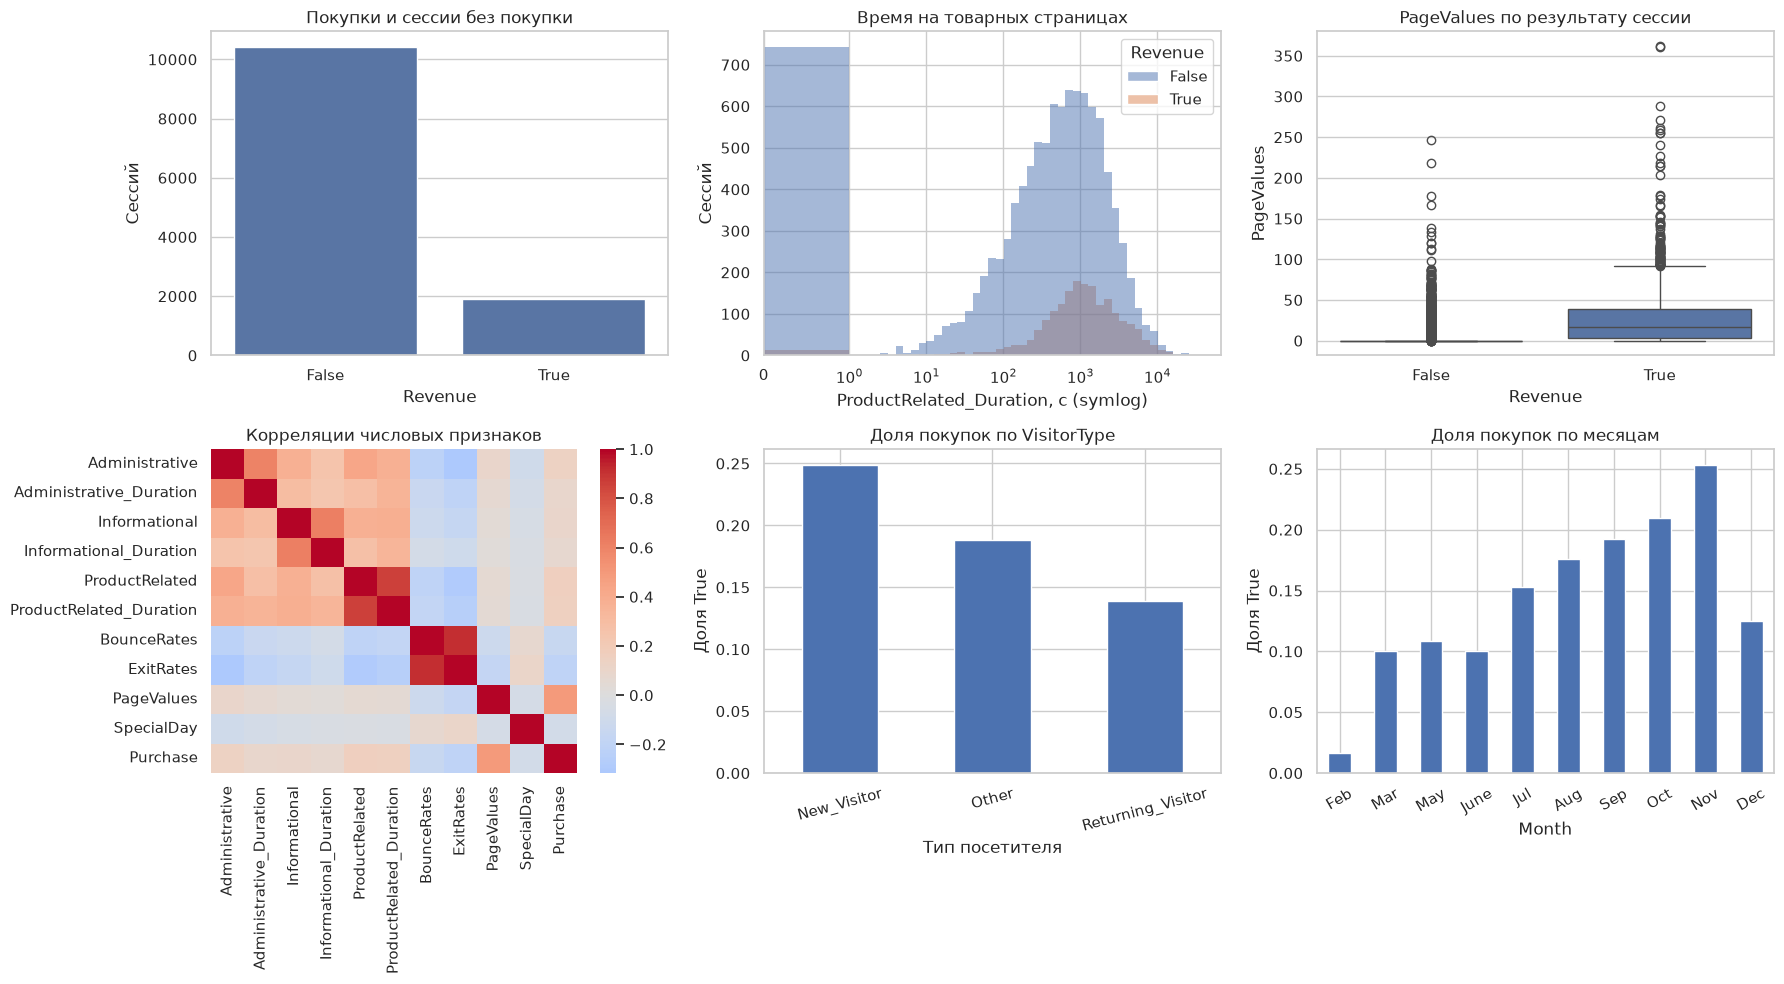

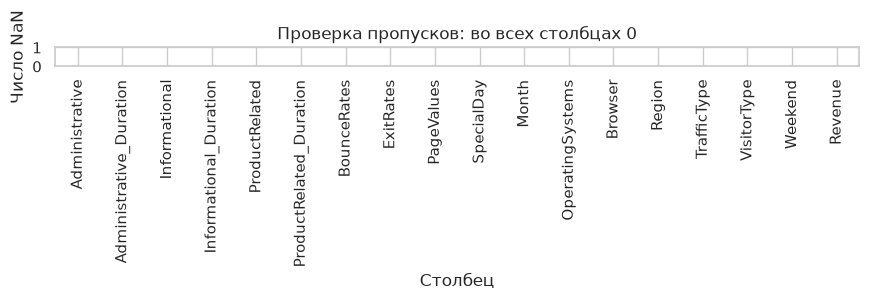

Исходных/после удаления повторов: 12330 12205
Классы после очистки: {False: 10297, True: 1908}
Train/test: (9764, 84) (2441, 84) доли покупок: 0.15628840639082342 0.15649324047521507
       TotalPages  TotalDuration  AvgPageValue  BounceExitRatio  IsNewVisitor  IsWeekend  MonthNum  IsHighTraffic
7556           51    1256.000000      0.718409              0.0             0          0        11              0
11924          30     901.288889      1.101562              0.0             1          0        12              0
3306           13     421.166667      0.000000              0.0             0          0         5              0
207             7     598.500000      0.000000              0.0             1          1         3              0
4460           16    1599.266667      0.000000              0.0             0          0         5              1


Random Forest: 1.621 сек


XGBoost: 0.717 сек


LightGBM: 0.396 сек


CatBoost: 2.135 сек
               accuracy  precision  recall      f1  roc_auc
Random Forest    0.8726     0.5617  0.8455  0.6750   0.9332
XGBoost          0.8791     0.5893  0.7513  0.6605   0.9300
LightGBM         0.8714     0.5632  0.7932  0.6587   0.9321
CatBoost         0.8734     0.5662  0.8168  0.6688   0.9328
Лидер исходного сравнения: Random Forest
Accuracy постоянного No: 0.8435067595247849


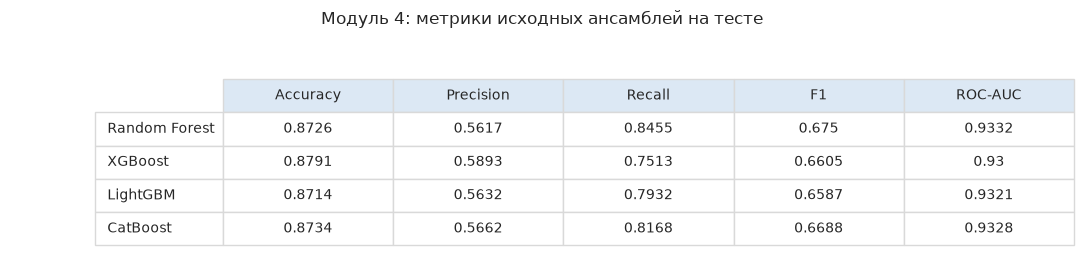

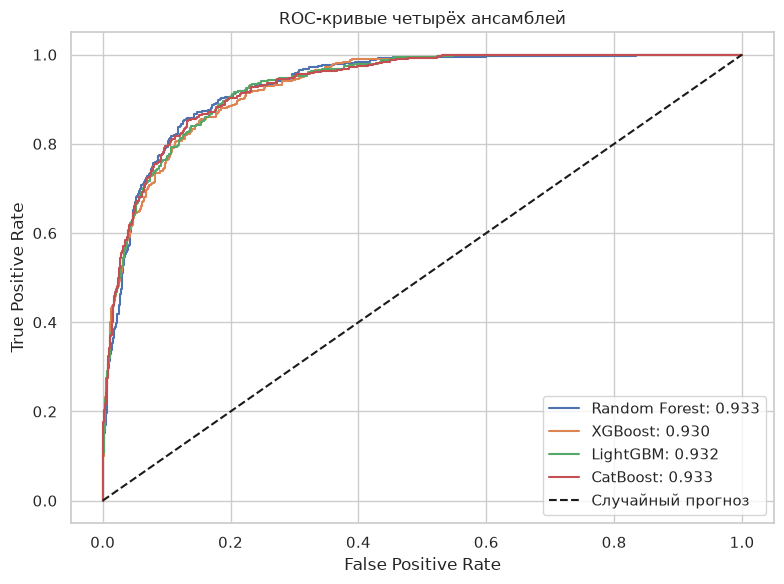

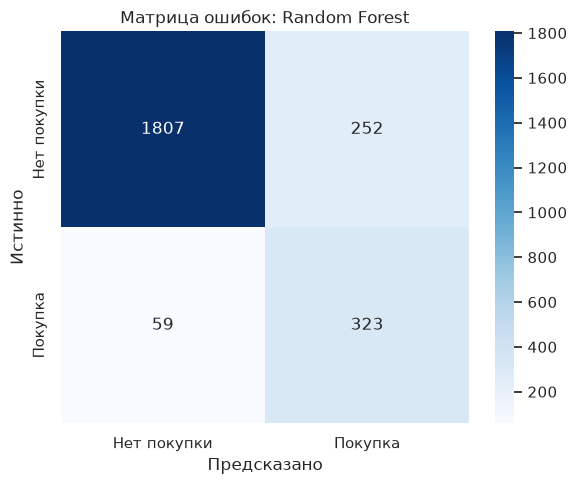

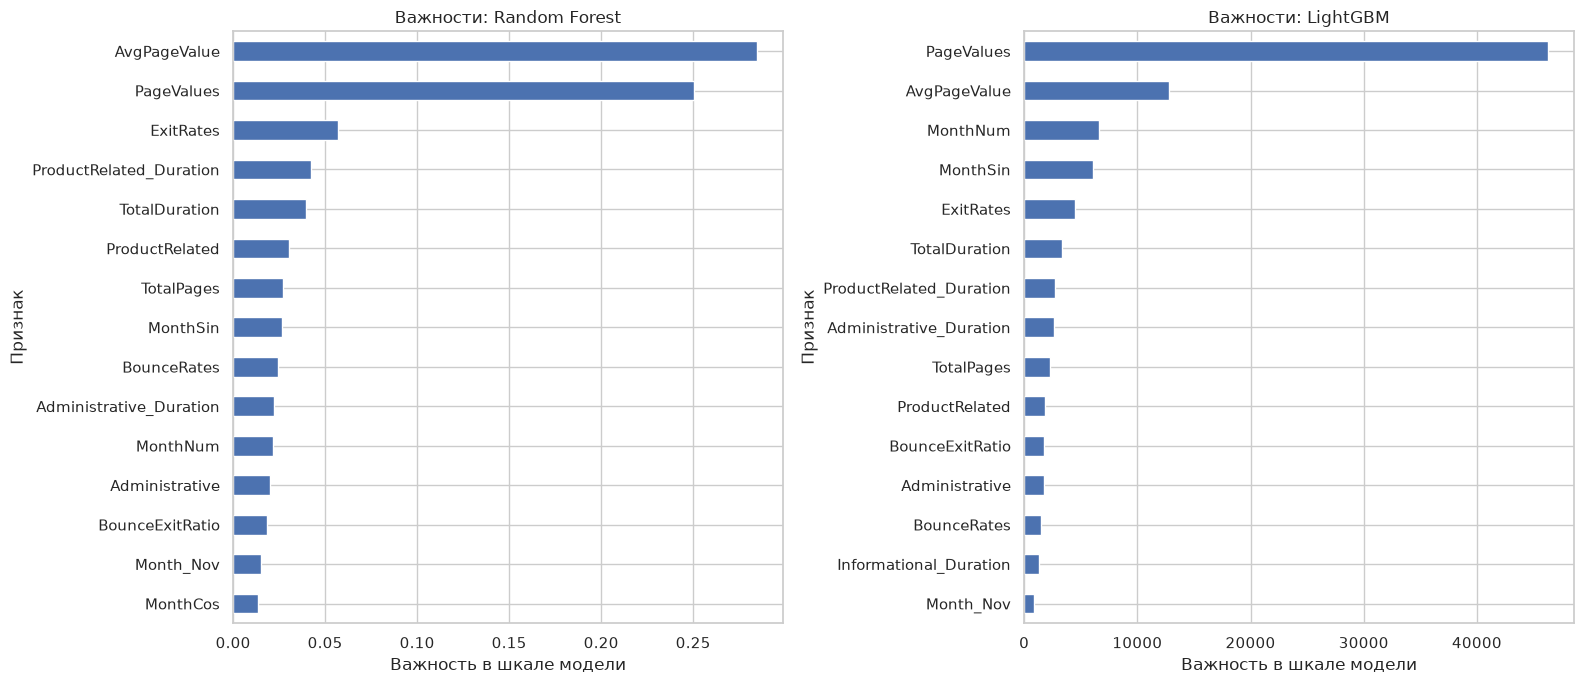

Посетители: {'mean': {'New_Visitor': 0.24911452184179456, 'Other': 0.18823529411764706, 'Returning_Visitor': 0.1393232868922377}, 'count': {'New_Visitor': 1694, 'Other': 85, 'Returning_Visitor': 10551}}
Месяцы: {'mean': {'Feb': 0.016304347826086956, 'Mar': 0.10068169900367069, 'May': 0.10850178359096314, 'June': 0.10069444444444445, 'Jul': 0.1527777777777778, 'Aug': 0.17551963048498845, 'Sep': 0.19196428571428573, 'Oct': 0.20947176684881602, 'Nov': 0.25350233488992663, 'Dec': 0.1250723798494499}, 'count': {'Feb': 184, 'Mar': 1907, 'May': 3364, 'June': 288, 'Jul': 432, 'Aug': 433, 'Sep': 448, 'Oct': 549, 'Nov': 2998, 'Dec': 1727}}
Топ-5 gain: {'PageValues': 46262.32089078761, 'AvgPageValue': 12835.452844581829, 'MonthNum': 6626.065413955638, 'MonthSin': 6065.971120179485, 'ExitRates': 4533.544330976031}


Feature Engineering CV: {
  "Original": {
    "mean": 0.9267753194507533,
    "std": 0.006597789820739376,
    "fold_scores": [
      0.9221440448269977,
      0.9194890975648575,
      0.9282667515518065,
      0.9385663695686773,
      0.9254103337414276
    ]
  },
  "Engineered": {
    "mean": 0.926886071120145,
    "std": 0.006670806471975471,
    "fold_scores": [
      0.923935775484045,
      0.9178000159159636,
      0.9265438484800255,
      0.9382957981855802,
      0.9278549175351111
    ]
  },
  "WithoutPageValues": {
    "mean": 0.7723829075978996,
    "std": 0.013287657260406769,
    "fold_scores": [
      0.7671246195300627,
      0.7556839885405061,
      0.7957623746617858,
      0.7754595734521725,
      0.7678839818049707
    ]
  }
}


C:\Users\lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Trials: 30 CV baseline: 0.926886071120145 CV Optuna: 0.9351712753763991
Test baseline: 0.9321342389051769 Test Optuna: 0.9365046571176472
Search seconds: 54.90311500000098 Final fit seconds: 0.36143079999965266
Best parameters: {
  "n_estimators": 200,
  "num_leaves": 30,
  "max_depth": 6,
  "learning_rate": 0.010625520240503112,
  "subsample": 0.8427691130411582,
  "colsample_bytree": 0.9312446855299032,
  "min_child_samples": 42,
  "reg_alpha": 0.813162965787202,
  "reg_lambda": 0.13700169099277154,
  "subsample_freq": 1
}
Метрики Optuna: {'accuracy': 0.8664481769766489, 'precision': 0.5469798657718121, 'recall': 0.8534031413612565, 'f1': 0.6666666666666666, 'roc_auc': 0.9365046571176472}


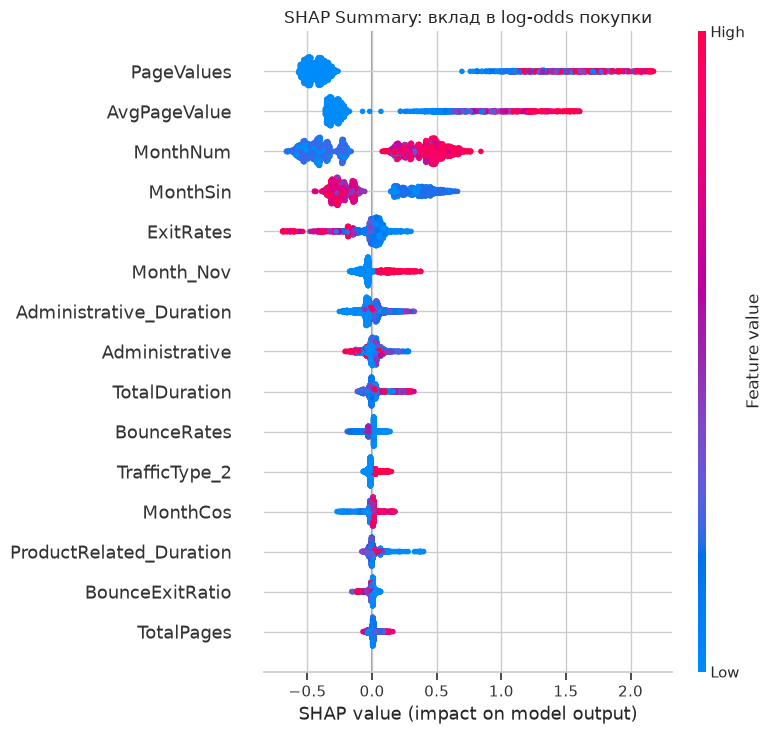

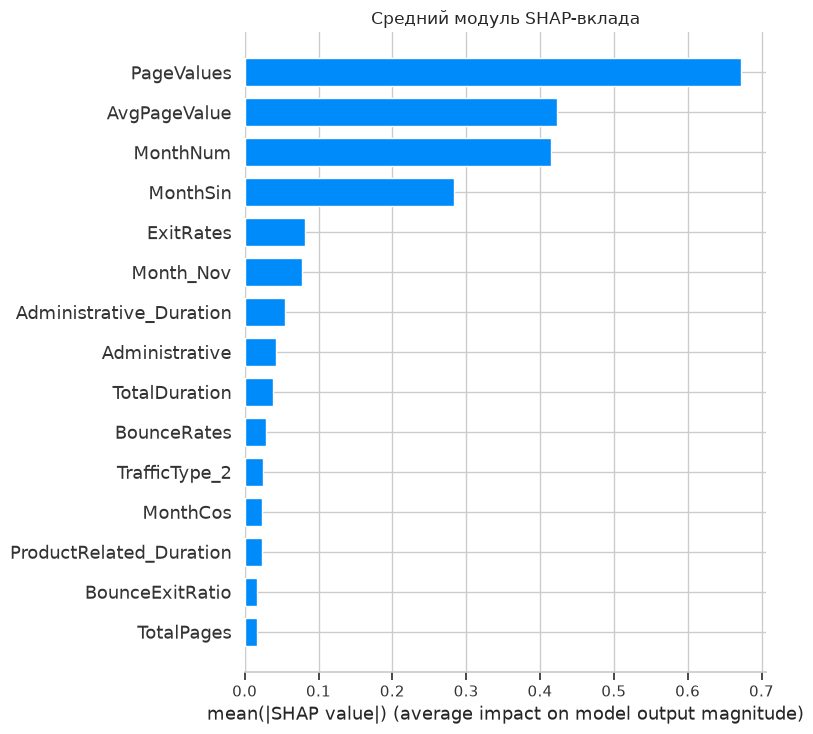

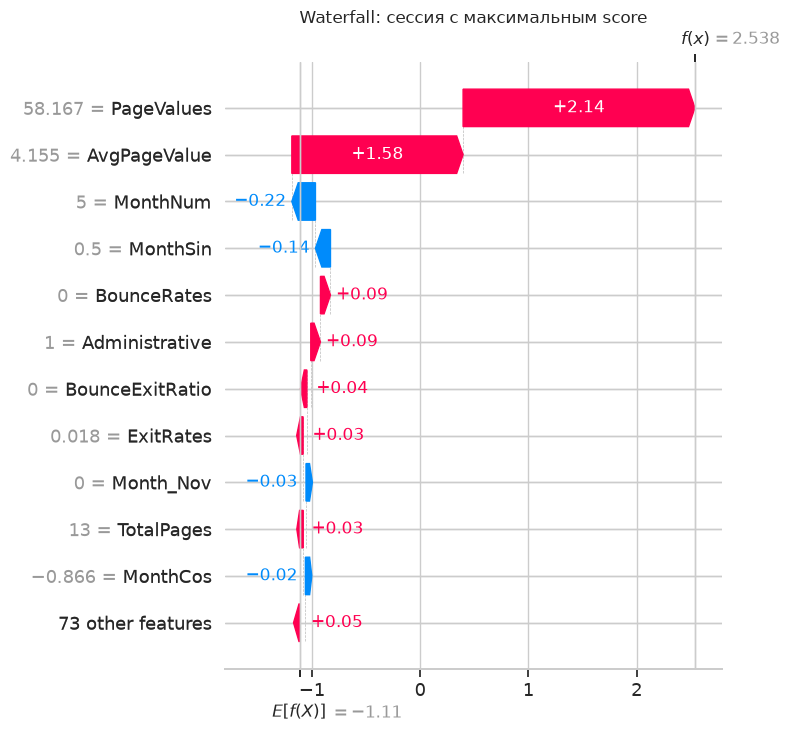

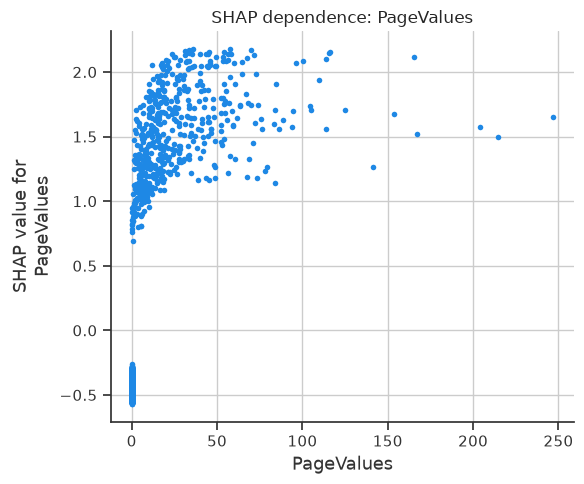

Топ SHAP: {'PageValues': 0.6727061430657791, 'AvgPageValue': 0.4227698962035738, 'MonthNum': 0.41424754901024075, 'MonthSin': 0.2828982082655887, 'ExitRates': 0.08230265452728597}
Сессия: 4865 модельный score покупки: 0.9267884012316291
Базовый raw score: -1.1100075942795486 Итоговый raw score: 2.5383714160893764
PageValues = 58.16727273 SHAP log-odds: 2.1415
AvgPageValue = 4.154805195 SHAP log-odds: 1.5818
MonthNum = 5.0 SHAP log-odds: -0.2181
MonthSin = 0.49999999999999994 SHAP log-odds: -0.1388
BounceRates = 0.0 SHAP log-odds: 0.0926


Сохранены: best_model.pkl, cat_model.pkl, encoder.pkl, feature_cols.json, lgbm_model.pkl, load_verification.json, metrics.json, optuna_trials.csv, preprocessor.json, report_details.json, rf_model.pkl, scaler.pkl, xgb_model.pkl
Локально загруженные вероятности совпали: [0.26735077 0.22998808 0.28742153]


GitHub raw: классы и вероятности совпали: [0.26735077 0.22998808 0.28742153]


161

In [21]:
# %%
# Импортируем средства анализа, обучения и сохранения артефактов.
import json  # Подключаем json
import time  # Подключаем time
import hashlib  # Подключаем hashlib
from io import BytesIO  # Подключаем io
from pathlib import Path  # Подключаем pathlib
from importlib.metadata import version  # Подключаем importlib.metadata
import joblib  # Подключаем joblib
import numpy as np  # Подключаем numpy
import pandas as pd  # Подключаем pandas
import matplotlib.pyplot as plt  # Подключаем matplotlib.pyplot
import seaborn as sns  # Подключаем seaborn
from sklearn.ensemble import RandomForestClassifier  # Подключаем sklearn.ensemble
from sklearn.model_selection import train_test_split, StratifiedKFold  # Подключаем sklearn.model_selection
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # Подключаем sklearn.preprocessing
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,  # Подключаем sklearn.metrics
                             roc_auc_score, confusion_matrix, roc_curve)
from xgboost import XGBClassifier  # Подключаем xgboost
from lightgbm import LGBMClassifier  # Подключаем lightgbm
from catboost import CatBoostClassifier  # Подключаем catboost

# Пути считаются относительно папки module-3-churn.
SEED = 42  # Фиксируем случайность
DATA, MODELS, EXAMPLES = Path('data'), Path('models'), Path('examples')  # Относительные папки
MODELS.mkdir(exist_ok=True)  # Артефакты моделей
EXAMPLES.mkdir(exist_ok=True)  # Папка рисунков
sns.set_theme(style='whitegrid', font='DejaVu Sans')  # Единый стиль

# Читаем исходную таблицу и проверяем обязательную структуру.
df = pd.read_csv(DATA / 'online_shoppers_intention.csv')
print(df.shape)  # Строки и столбцы.
print(df.head().to_string(index=False))  # Первые сессии.
assert df.shape == (12330, 18)  # Размер по заданию.
print(df.Revenue.value_counts().to_string())  # Число классов.
print((100*df.Revenue.value_counts(normalize=True)).round(2).to_string())  # Доли.

# %%
# Осматриваем типы и распределения исходных измерений.
df.info()  # Типы и заполненность.
print(df.describe(include='all').to_string())  # Числа и категории.
print('Пропуски:', df.isna().sum().to_dict())  # Полная проверка NaN.
print('Повторяющиеся строки:', int(df.duplicated().sum()))  # Диагностика.
eda = df.copy()  # Сохраняем исходный размер для EDA.
eda['Purchase'] = eda.Revenue.astype(int)  # Доля покупки в группе.
months = {'Jan':1,'Feb':2,'Mar':3,'Apr':4,'May':5,'June':6,'Jun':6,'Jul':7,'Aug':8,'Sep':9,'Oct':10,'Nov':11,'Dec':12}  # Календарь.
numeric = ['Administrative','Administrative_Duration','Informational','Informational_Duration','ProductRelated','ProductRelated_Duration','BounceRates','ExitRates','PageValues','SpecialDay']  # Числа.

# Шесть требуемых графиков с подписями.
fig, axes = plt.subplots(2, 3, figsize=(18, 10))  # Сетка.
sns.countplot(data=eda, x='Revenue', ax=axes[0,0])  # Классы.
axes[0,0].set(title='Покупки и сессии без покупки', xlabel='Revenue', ylabel='Сессий')  # Оси.
sns.histplot(data=eda, x='ProductRelated_Duration', hue='Revenue', bins=np.r_[0,np.geomspace(1,eda.ProductRelated_Duration.max(),49)], ax=axes[0,1])  # Время.
axes[0,1].set_xscale('symlog',linthresh=1)  # Показываем нули и длинный хвост без удаления строк.
axes[0,1].set_xlim(0, float(eda.ProductRelated_Duration.max())*1.05)  # Отрицательных длительностей нет.
axes[0,1].set(title='Время на товарных страницах', xlabel='ProductRelated_Duration, с (symlog)', ylabel='Сессий')  # Оси.
sns.boxplot(data=eda, x='Revenue', y='PageValues', ax=axes[0,2])  # Ценность.
axes[0,2].set(title='PageValues по результату сессии', xlabel='Revenue', ylabel='PageValues')  # Оси.
sns.heatmap(eda[numeric+['Purchase']].corr(), cmap='coolwarm', center=0, ax=axes[1,0])  # Связи.
axes[1,0].set_title('Корреляции числовых признаков')  # Название.
eda.groupby('VisitorType').Purchase.mean().plot.bar(ax=axes[1,1], rot=15)  # Тип посетителя.
axes[1,1].set(title='Доля покупок по VisitorType', xlabel='Тип посетителя', ylabel='Доля True')  # Оси.
month_order = sorted(eda.Month.unique(), key=lambda value: months[value])  # Календарный порядок.
eda.groupby('Month').Purchase.mean().reindex(month_order).plot.bar(ax=axes[1,2], rot=30)  # Месяцы.
axes[1,2].set(title='Доля покупок по месяцам', xlabel='Month', ylabel='Доля True')  # Оси.
fig.tight_layout()  # Защита подписей.
fig.savefig(EXAMPLES/'eda_plots.png', dpi=140, bbox_inches='tight')  # Артефакт.
plt.show()  # Рисунок в ноутбуке.

# Визуализируем нулевые количества пропусков, не выдумывая NaN.
fig, ax = plt.subplots(figsize=(9,3))  # Компактный график.
df.isna().sum().plot.bar(ax=ax)  # Число NaN по всем полям.
ax.set(title='Проверка пропусков: во всех столбцах 0', xlabel='Столбец', ylabel='Число NaN', ylim=(0,1))  # Оси.
fig.tight_layout()  # Поля.
fig.savefig(EXAMPLES/'missing_values.png', dpi=140)  # Сохранение.
plt.show()  # Вывод.

# %%
# Удаляем только полные повторы, затем делим с сохранением классов.
clean_df = df.drop_duplicates().copy()  # Прозрачное правило очистки.
y = clean_df.Revenue.astype(int)  # Покупка равна единице.
raw_train, raw_test, y_train, y_test = train_test_split(clean_df.drop(columns='Revenue'), y,
    test_size=0.2, random_state=SEED, stratify=y)  # Отложенная выборка.
CAT_COLS = ['Month','OperatingSystems','Browser','Region','TrafficType','VisitorType','Weekend']  # Смысловые категории.

# Создаём все восемь обязательных и два циклических признака.
def engineer_sessions(raw):
    x = raw.drop(columns='Revenue', errors='ignore').copy()  # Исключаем цель.
    x['TotalPages'] = x.Administrative+x.Informational+x.ProductRelated  # Общие страницы.
    x['TotalDuration'] = x.Administrative_Duration+x.Informational_Duration+x.ProductRelated_Duration  # Время.
    x['AvgPageValue'] = x.PageValues/(x.TotalPages+1)  # Ценность на объём.
    x['BounceExitRatio'] = x.BounceRates/(x.ExitRates+0.001)  # Защищённое отношение.
    x['IsNewVisitor'] = x.VisitorType.eq('New_Visitor').astype(int)  # Новый посетитель.
    x['IsWeekend'] = x.Weekend.astype(int)  # Выходной.
    x['MonthNum'] = x.Month.map(months)  # Календарный словарь.
    if x.MonthNum.isna().any(): raise ValueError('Неизвестное название месяца')  # Не скрываем ошибку.
    x['IsHighTraffic'] = x.TrafficType.gt(10).astype(int)  # Группа кодов по условию.
    x['MonthSin'] = np.sin(2*np.pi*x.MonthNum/12)  # Цикл.
    x['MonthCos'] = np.cos(2*np.pi*x.MonthNum/12)  # Вторая координата цикла.
    return x  # Возвращаем расширенный набор.

# Обучаем One-Hot и резервные медианы исключительно на обучающей части.
def fit_preprocessing(raw, use_engineering=True, exclude_value=False):
    x = engineer_sessions(raw) if use_engineering else raw.copy()  # Вариант сравнения.
    if exclude_value: x = x.drop(columns=['PageValues','AvgPageValue'], errors='ignore')  # Проверка чувствительности.
    num_cols = [c for c in x if c not in CAT_COLS]  # Числа отдельно от категорий.
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(x[CAT_COLS].astype(str))  # Только train.
    columns = num_cols+list(encoder.get_feature_names_out(CAT_COLS))  # Порядок колонок.
    prep = {'use_engineering':use_engineering,'exclude_value':exclude_value,'num_cols':num_cols,
            'medians':{c:float(x[c].median()) for c in num_cols},'feature_cols':columns}  # JSON-параметры.
    return prep, encoder  # Состояние для инференса.

# Используем сохранённое состояние для теста и новых сессий.
def transform_sessions(raw, prep, encoder):
    x = engineer_sessions(raw) if prep['use_engineering'] else raw.copy()  # Те же формулы.
    numeric_part = x[prep['num_cols']].fillna(prep['medians']).astype(float)  # Резервная импутация.
    categorical = pd.DataFrame(encoder.transform(x[CAT_COLS].astype(str)), index=x.index,
        columns=encoder.get_feature_names_out(CAT_COLS))  # Без обучения на test.
    return pd.concat([numeric_part,categorical],axis=1).reindex(columns=prep['feature_cols']).astype(float)  # Порядок.

# Матрицы и scaler подготовлены без утечки из теста.
preprocessor, encoder = fit_preprocessing(raw_train)  # Fit только train.
X_train = transform_sessions(raw_train, preprocessor, encoder)  # Обучающие признаки.
X_test = transform_sessions(raw_test, preprocessor, encoder)  # Отложенные признаки.
feature_cols = list(X_train.columns)  # Порядок.
scaler = StandardScaler().fit(X_train)  # Сохраняется по заданию; деревья используют исходный масштаб.
assert not X_train.isna().any().any() and not X_test.isna().any().any()  # Полнота.
assert not set(map(tuple,raw_train.to_numpy())).intersection(map(tuple,raw_test.to_numpy()))  # Нет точных копий между частями.
print('Исходных/после удаления повторов:', len(df),len(clean_df))  # Размер.
print('Классы после очистки:', clean_df.Revenue.value_counts().to_dict())  # Пропорции.
print('Train/test:', X_train.shape,X_test.shape, 'доли покупок:',y_train.mean(),y_test.mean())  # Проверка.
print(engineer_sessions(raw_train)[['TotalPages','TotalDuration','AvgPageValue','BounceExitRatio','IsNewVisitor','IsWeekend','MonthNum','IsHighTraffic']].head().to_string())  # Восемь формул.

# %%
# Четыре модели используют одинаковые признаки и фиксированный seed.
class_ratio = float((y_train == 0).sum() / (y_train == 1).sum())  # Баланс только по train
models = {
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=10,  # Bagging с весами
        class_weight='balanced', random_state=SEED, n_jobs=2),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,  # Взвешенный бустинг
        subsample=0.9, colsample_bytree=0.9, scale_pos_weight=class_ratio,
        random_state=SEED, eval_metric='logloss', n_jobs=2),
    'LightGBM': LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7,  # Гистограммный бустинг
        learning_rate=0.05, class_weight='balanced', random_state=SEED,
        verbosity=-1, n_jobs=2, importance_type='gain'),
    'CatBoost': CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1,  # Балансировка классов
        auto_class_weights='Balanced', random_seed=SEED, verbose=False,
        thread_count=2, allow_writing_files=False)
}

# Фиксируем реальное время каждого обучения.
fit_times = {}
for name, model in models.items():
    started = time.perf_counter()  # Измеряем время
    model.fit(X_train, y_train)  # Обучаем на train
    fit_times[name] = time.perf_counter() - started  # Длительность fit
    print(f'{name}: {fit_times[name]:.3f} сек')

# %%
# Единая функция обеспечивает сопоставимость всех метрик.
def evaluate(model, x, target):
    proba = model.predict_proba(x)[:, 1]  # Риск положительного класса
    pred = (proba >= 0.5).astype(int)  # Общий порог
    return {'accuracy': float(accuracy_score(target, pred)),
            'precision': float(precision_score(target, pred, zero_division=0)),  # Точность среди предсказанных покупок
            'recall': float(recall_score(target, pred, zero_division=0)),  # Доля найденных покупок
            'f1': float(f1_score(target, pred, zero_division=0)),  # Баланс Precision и Recall
            'roc_auc': float(roc_auc_score(target, proba))}  # Ранжирование по вероятностям

# Отложенные метрики не используются для настройки параметров.
baseline_metrics = {name: evaluate(model, X_test, y_test) for name, model in models.items()}  # Единая тестовая оценка
results_df = pd.DataFrame(baseline_metrics).T  # Таблица метрик
baseline_winner = results_df.roc_auc.idxmax()  # Лидер baseline
print(results_df.round(4).to_string())
print('Лидер исходного сравнения:', baseline_winner)
print('Accuracy постоянного No:', float((y_test == 0).mean()))


# Сохраняем таблицу метрик отдельным изображением для приложения к сдаче.
fig,ax = plt.subplots(figsize=(11,2.8))
ax.axis('off')  # Таблица без координатных осей.
display_table = results_df.rename(columns={'accuracy':'Accuracy','precision':'Precision','recall':'Recall','f1':'F1','roc_auc':'ROC-AUC'})
tab = ax.table(cellText=display_table.round(4).values,rowLabels=display_table.index,colLabels=display_table.columns,
               cellLoc='center',loc='center',bbox=[0.20,0.04,0.80,0.78])  # Те же значения, что в коде.
tab.auto_set_font_size(False)
tab.set_fontsize(10)  # Читаемые числа.
for (row,col),cell in tab.get_celld().items():
    cell.set_edgecolor('#D9D9D9')  # Видимые границы.
    if row==0:
        cell.set_facecolor('#DCE8F4')  # Заголовок.
ax.set_title('Модуль 4: метрики исходных ансамблей на тесте',pad=12)
fig.tight_layout()  # Не обрезаем названия.
fig.savefig(EXAMPLES/'metrics_table.png',dpi=160,bbox_inches='tight')
plt.show()  # Таблица видна и в ноутбуке.

# Сравниваем четыре ROC-кривые на общей шкале.
fig, ax = plt.subplots(figsize=(8, 6))  # Отдельный рисунок
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])  # ROC по вероятностям
    ax.plot(fpr, tpr, label=f"{name}: {baseline_metrics[name]['roc_auc']:.3f}")  # Рисуем кривую
ax.plot([0, 1], [0, 1], 'k--', label='Случайный прогноз')  # Рисуем кривую
ax.set(title='ROC-кривые четырёх ансамблей', xlabel='False Positive Rate', ylabel='True Positive Rate')  # Названия осей
ax.legend(loc='lower right')  # Подписываем модели
fig.tight_layout()  # Защита от наложений
fig.savefig(EXAMPLES / 'roc_curves.png', dpi=140)  # Сохраняем артефакт
plt.show()  # Показываем график

# Матрица показывает пропущенные уходы и ложные тревоги.
winner_pred = (models[baseline_winner].predict_proba(X_test)[:, 1] >= 0.5).astype(int)  # Порог 0,5
baseline_cm = confusion_matrix(y_test, winner_pred)  # TN, FP, FN, TP
fig, ax = plt.subplots(figsize=(6, 5))  # Отдельный рисунок
sns.heatmap(baseline_cm, annot=True, fmt='d', cmap='Blues', ax=ax,
    xticklabels=['Нет покупки', 'Покупка'], yticklabels=['Нет покупки', 'Покупка'])
ax.set(title=f'Матрица ошибок: {baseline_winner}', xlabel='Предсказано', ylabel='Истинно')  # Названия осей
fig.tight_layout()  # Защита от наложений
fig.savefig(EXAMPLES / 'confusion_matrix.png', dpi=140)  # Сохраняем артефакт
plt.show()  # Показываем график

# %%
# Важности разных алгоритмов не сравниваются в абсолютных единицах.
importance_tables = {name:pd.Series(models[name].feature_importances_,index=feature_cols).sort_values(ascending=False)
    for name in ['Random Forest','LightGBM']}  # Отдельные шкалы.
fig, axes = plt.subplots(1,2,figsize=(16,7))  # Два алгоритма.
for ax,(name,values) in zip(axes,importance_tables.items()):
    values.head(15).sort_values().plot.barh(ax=ax)  # Топ-15.
    ax.set(title=f'Важности: {name}',xlabel='Важность в шкале модели',ylabel='Признак')  # Оси.
fig.tight_layout()  # Поля.
fig.savefig(EXAMPLES/'feature_importance.png',dpi=140)  # Артефакт.
plt.show()  # Вывод.

# Наблюдаемые доли покупки для бизнес-интерпретации.
visitor_rates = eda.groupby('VisitorType').Purchase.agg(['mean','count'])  # Типы посетителей.
month_rates = eda.groupby('Month').Purchase.agg(['mean','count']).reindex(month_order)  # Месяцы.
print('Посетители:',visitor_rates.to_dict())  # Доли и размеры.
print('Месяцы:',month_rates.to_dict())  # Сезонность.
print('Топ-5 gain:',importance_tables['LightGBM'].head(5).to_dict())  # Важности.

# Контролируемое сравнение только на train, без настройки по test.
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)  # Общие блоки.
cv_indices = list(cv.split(raw_train,y_train))  # Один и тот же набор разбиений.
def make_cv_data(use_engineering=True,exclude_value=False):
    folds=[]  # Матрицы блоков.
    for fit_ids,val_ids in cv_indices:
        fit_raw,val_raw=raw_train.iloc[fit_ids],raw_train.iloc[val_ids]  # Сырые строки.
        prep,enc=fit_preprocessing(fit_raw,use_engineering,exclude_value)  # Только CV-train.
        folds.append((transform_sessions(fit_raw,prep,enc),y_train.iloc[fit_ids],
                      transform_sessions(val_raw,prep,enc),y_train.iloc[val_ids]))  # Сохраняем блок.
    return folds  # Общая структура для сравнения.

# Одни гиперпараметры baseline применяются ко всем представлениям.
fixed_lgbm = dict(class_weight='balanced',random_state=SEED,verbosity=-1,n_jobs=2,importance_type='gain')  # Фиксировано.
baseline_params = dict(n_estimators=200,num_leaves=31,max_depth=7,learning_rate=0.05)  # По заданию.
def score_folds(params,folds):
    scores=[]  # AUC блоков.
    for xf,yf,xv,yv in folds:
        estimator=LGBMClassifier(**params,**fixed_lgbm).fit(xf,yf)  # Fit CV-train.
        scores.append(roc_auc_score(yv,estimator.predict_proba(xv)[:,1]))  # AUC CV-validation.
    return scores  # Сохраняем распределение оценок.

cv_data = make_cv_data()  # Расширенные признаки для последующего Optuna.
feature_experiment = {}  # Результаты трёх режимов.
for label,folds in [('Original',make_cv_data(False)),('Engineered',cv_data),('WithoutPageValues',make_cv_data(True,True))]:
    scores=score_folds(baseline_params,folds)  # Контролируем только представление.
    feature_experiment[label]={'mean':float(np.mean(scores)),'std':float(np.std(scores)),'fold_scores':list(map(float,scores))}  # CV.
print('Feature Engineering CV:',json.dumps(feature_experiment,indent=2))  # Измеренный эффект.

# %%
import optuna  # Поиск гиперпараметров
optuna.logging.set_verbosity(optuna.logging.WARNING)
# Одни настройки воспроизводимости применяются ко всем trial.
fixed_lgbm = dict(class_weight='balanced', random_state=SEED, verbosity=-1, n_jobs=2, importance_type='gain')  # Общие параметры
def cv_auc(params):
    scores = []  # Оценки блоков
    for x_fit, y_fit, x_val, y_val in cv_data:
        candidate = LGBMClassifier(**params, **fixed_lgbm).fit(x_fit, y_fit)  # Fit на CV-train
        scores.append(roc_auc_score(y_val, candidate.predict_proba(x_val)[:, 1]))  # AUC на CV-validation
    return float(np.mean(scores))

# Baseline оценивается на тех же пяти блоках.
baseline_params = dict(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05)  # Исходный LightGBM
baseline_cv_auc = cv_auc(baseline_params)  # Те же CV-блоки
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),  # Число деревьев
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),  # Максимум листьев
        'max_depth': trial.suggest_int('max_depth', 3, 12),  # Глубина
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),  # Темп
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),  # Доля строк
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),  # Доля признаков
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),  # Минимум строк в листе
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),  # L1
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),  # L2
        'subsample_freq': 1}  # Включаем подвыборку
    return cv_auc(params)

# TPE использует результаты train CV и фиксированный seed.
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))  # TPE с seed
started = time.perf_counter()  # Измеряем время
study.optimize(objective, n_trials=30, n_jobs=1, show_progress_bar=False)  # 30 испытаний train CV
search_time = time.perf_counter() - started  # Время поиска
best_params = {**study.best_params, 'subsample_freq': 1}  # Выигравший trial
best_model = LGBMClassifier(**best_params, **fixed_lgbm)  # Финальный LightGBM
started = time.perf_counter()  # Измеряем время
best_model.fit(X_train, y_train)  # Весь train
tuned_fit_time = time.perf_counter() - started  # Время финального fit
tuned_metrics = evaluate(best_model, X_test, y_test)  # Отложенная оценка

# Разделяем train CV и единую тестовую оценку.
print('Trials:', len(study.trials), 'CV baseline:', baseline_cv_auc, 'CV Optuna:', study.best_value)
print('Test baseline:', baseline_metrics['LightGBM']['roc_auc'], 'Test Optuna:', tuned_metrics['roc_auc'])
print('Search seconds:', search_time, 'Final fit seconds:', tuned_fit_time)
print('Best parameters:', json.dumps(best_params, indent=2))
print('Метрики Optuna:', tuned_metrics)
study.trials_dataframe().to_csv(MODELS / 'optuna_trials.csv', index=False)  # Полная история

# %%
# Рассчитываем SHAP и учитываем возможные формы бинарного выхода.
import shap  # Подключаем shap
explainer = shap.TreeExplainer(best_model, model_output='raw')  # Шкала raw score
explanation = explainer(X_test)  # Все тестовые клиенты
shap_values = np.asarray(explanation.values)  # Значения Шепли
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]  # Значения Шепли
base_values = np.asarray(explanation.base_values)  # Базовый выход
if base_values.ndim == 2:
    base_values = base_values[:, 1]  # Базовый выход
base_values = np.broadcast_to(base_values, len(X_test))  # Базовый выход
raw_scores = best_model.predict(X_test, raw_score=True)  # Проверяем log-odds
assert np.allclose(base_values + shap_values.sum(axis=1), raw_scores, atol=1e-6)

# Summary и bar показывают глобальное распределение вкладов.
shap.summary_plot(shap_values, X_test, show=False, max_display=15)  # Глобальные вклады
plt.title('SHAP Summary: вклад в log-odds покупки')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_summary.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график
shap.summary_plot(shap_values, X_test, plot_type='bar', show=False, max_display=15)  # Глобальные вклады
plt.title('Средний модуль SHAP-вклада')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_bar.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график

# Waterfall объясняет сессию с максимальным модельным шансом покупки.
tuned_proba = best_model.predict_proba(X_test)[:, 1]  # Модельный score покупки
worst_idx = int(np.argmax(tuned_proba))  # Максимальный score покупки
local_explanation = shap.Explanation(values=shap_values[worst_idx], base_values=base_values[worst_idx],  # Объяснение одного сессию
    data=X_test.iloc[worst_idx].to_numpy(), feature_names=feature_cols)
shap.plots.waterfall(local_explanation, max_display=12, show=False)  # Локальные вклады
plt.title('Waterfall: сессия с максимальным score')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_waterfall.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график

# Dependence использует ведущий признак по среднему модулю SHAP.
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_cols).sort_values(ascending=False)  # Средний модуль вкладов
top_feature = str(shap_importance.index[0])  # Ведущий SHAP-признак
shap.dependence_plot(top_feature, shap_values, X_test, interaction_index=None, show=False)  # Вклад в зависимости от входа
plt.title(f'SHAP dependence: {top_feature}')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_dependence.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график

# Для локального случая печатаем исходные значения, а не только коды.
local_top = pd.Series(shap_values[worst_idx], index=feature_cols).sort_values(key=np.abs, ascending=False).head(5)  # Пять сильнейших вкладов
print('Топ SHAP:', shap_importance.head(5).to_dict())
print('Сессия:', str(raw_test.index[worst_idx]), 'модельный score покупки:', tuned_proba[worst_idx])
print('Базовый raw score:', base_values[worst_idx], 'Итоговый raw score:', raw_scores[worst_idx])
for field, contribution in local_top.items():
    raw_value = raw_test.iloc[worst_idx].get(field, X_test.iloc[worst_idx][field])  # Исходная категория
    print(field, '=', raw_value, 'SHAP log-odds:', round(contribution, 4))

# %%
# Сохраняем стандартные модели без пользовательских классов в pickle.
file_names={'Random Forest':'rf_model.pkl','XGBoost':'xgb_model.pkl','LightGBM':'lgbm_model.pkl','CatBoost':'cat_model.pkl'}  # Имена.
for name,filename in file_names.items():
    joblib.dump(models[name],MODELS/filename,compress=3)  # Базовые модели.
joblib.dump(best_model,MODELS/'best_model.pkl',compress=3)  # Выбранный CV trial.
joblib.dump(scaler,MODELS/'scaler.pkl',compress=3)  # По структуре задания.
joblib.dump(encoder,MODELS/'encoder.pkl',compress=3)  # Стандартный OneHotEncoder.
(MODELS/'feature_cols.json').write_text(json.dumps(feature_cols,ensure_ascii=False,indent=2),encoding='utf-8')  # Порядок.
(MODELS/'preprocessor.json').write_text(json.dumps(preprocessor,ensure_ascii=False,indent=2),encoding='utf-8')  # Медианы и режим.

# Версии и фактические метрики позволяют повторить эксперимент.
packages=['pandas','numpy','scikit-learn','xgboost','lightgbm','catboost','optuna','shap','matplotlib','seaborn','joblib','requests']  # Пакеты.
versions={p:version(p) for p in packages}  # Реальные версии.
metrics={'baseline':baseline_metrics,'fit_time_sec':fit_times,'tuned':tuned_metrics,'best_model':'LightGBM (Optuna)',
    'baseline_test_winner':baseline_winner,'cv_baseline_roc_auc':baseline_cv_auc,'cv_best_roc_auc':float(study.best_value),
    'best_params':best_params,'n_trials':len(study.trials),'cv_folds':5,'search_time_sec':search_time,
    'tuned_fit_time_sec':tuned_fit_time,'source_rows':len(df),'clean_rows':len(clean_df),'removed_duplicates':len(df)-len(clean_df),
    'train_rows':len(X_train),'test_rows':len(X_test),'feature_count':len(feature_cols),'seed':SEED,'threshold':0.5,
    'training_date':'2026-11-02','versions':versions,'feature_experiment':feature_experiment,
    'data_sha256':hashlib.sha256((DATA/'online_shoppers_intention.csv').read_bytes()).hexdigest()}  # Все условия.
(MODELS/'metrics.json').write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding='utf-8')  # Метаданные.
report={'metrics':metrics,'visitor_rates':visitor_rates.to_dict(),'month_rates':month_rates.to_dict(),
    'baseline_cm':baseline_cm.tolist(),'importance':importance_tables['LightGBM'].head(5).to_dict(),
    'shap_top':shap_importance.head(5).to_dict(),'shap_feature':top_feature,'best_session':int(raw_test.index[worst_idx]),
    'best_probability':float(tuned_proba[worst_idx]),
    'local_shap':{field:{'value':float(value),'raw_value':str(raw_test.iloc[worst_idx].get(field,X_test.iloc[worst_idx][field]))}
                  for field,value in local_top.items()}}  # Числа для Markdown.
(MODELS/'report_details.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')  # Проверяемые выводы.
print('Сохранены:',', '.join(sorted(p.name for p in MODELS.iterdir())))  # Список артефактов.

# %%
# Проверяем путь от исходной сессии до загруженной модели.
loaded_model = joblib.load(MODELS / 'best_model.pkl')  # Без повторного fit
loaded_encoder = joblib.load(MODELS / 'encoder.pkl')  # Словари категорий
loaded_prep = json.loads((MODELS / 'preprocessor.json').read_text(encoding='utf-8'))  # Обучающая медиана
loaded_features = json.loads((MODELS / 'feature_cols.json').read_text(encoding='utf-8'))  # Порядок колонок
three_clients = transform_sessions(raw_test.iloc[:3], loaded_prep, loaded_encoder)[loaded_features]  # Три исходных сессии
original_proba = best_model.predict_proba(X_test.iloc[:3])[:, 1]  # Эталон модели
loaded_proba = loaded_model.predict_proba(three_clients)[:, 1]  # После joblib.load
assert np.allclose(original_proba, loaded_proba, rtol=0, atol=1e-12)
assert np.array_equal(best_model.predict(X_test.iloc[:3]), loaded_model.predict(three_clients))
print('Локально загруженные вероятности совпали:', loaded_proba)

# Проверяем HTTP-ответ до чтения модельного файла.
import requests  # Подключаем requests
BASE_URL = 'https://raw.githubusercontent.com/VolodinaAlexandra/ml-course-volodina/main/module-4-features'  # Папка модуля в main
def load_from_repository(base_url=BASE_URL):
    def download(path):
        response = requests.get(f'{base_url}/{path}', timeout=30,
                                params={'verification': time.time_ns()})  # HTTP с таймаутом
        response.raise_for_status()  # Отсекаем 404 до чтения pickle
        return response.content
    model = joblib.load(BytesIO(download('models/best_model.pkl')))  # Опубликованная модель
    encoder = joblib.load(BytesIO(download('models/encoder.pkl')))  # Отдельный словарь для каждого поля
    prep = json.loads(download('models/preprocessor.json').decode('utf-8'))  # Медиана обучения
    features = json.loads(download('models/feature_cols.json').decode('utf-8'))  # Порядок признаков
    return model, encoder, prep, features

# До публикации 404 фиксируется честно; после публикации проверка выполняется автоматически.
remote_status = 'not_published'  # Явный статус
try:
    remote_model, remote_encoder, remote_prep, remote_features = load_from_repository()  # Попытка raw-загрузки
except requests.HTTPError as error:
    if error.response.status_code != 404:  # 404 означает отсутствие файла
        raise
    print('GitHub raw: HTTP 404 — модуль 4 ещё не опубликован. Локальная проверка пройдена.')
else:
    remote_x = transform_sessions(raw_test.iloc[:3], remote_prep, remote_encoder)[remote_features]  # Те же преобразования
    remote_proba = remote_model.predict_proba(remote_x)[:, 1]  # Удалённый прогноз
    assert np.allclose(original_proba, remote_proba, rtol=0, atol=1e-10)
    assert np.array_equal(best_model.predict(X_test.iloc[:3]), remote_model.predict(remote_x))
    remote_status = 'verified'  # Явный статус
    print('GitHub raw: классы и вероятности совпали:', remote_proba)

# Сохраняем статус, не требующий чтения графиков.
verification = {'local_equal': True, 'local_probabilities': loaded_proba.tolist(), 'remote_status': remote_status}  # Фактический статус проверки
(MODELS / 'load_verification.json').write_text(json.dumps(verification, ensure_ascii=False, indent=2), encoding='utf-8')
